# Лабораторная работа №5
## Градиентный бустинг

В этой работе я исследую градиентный бустинг для классификации кредитных заявок и прогноза
прочности бетона. Продолжаю работы №1–4: сохраняю исходные данные, признаки, train/test,
CV-фолды и метрики. Проверяю гипотезы на train, реализую алгоритм самостоятельно и
подвожу итоги сравнения **всех пяти алгоритмов**.

| Задача | Модель sklearn | Цель | Основная метрика |
|:--|:--|:--|:--|
| Историческое одобрение заявки | GradientBoostingClassifier, log-loss | `loan_status` | F1 ↑ |
| Прочность новой рецептуры | GradientBoostingRegressor, squared_error | `strength`, МПа | MAE ↓ |

Для каждой задачи сравню **четыре обязательных варианта**: исходный и улучшенный sklearn,
исходную и улучшенную собственную модель. Dummy служит простым ориентиром.
Все итоговые модели обучаются на полном train: **36 000 заявок / 799 измерений бетона**;
test содержит **9 000 / 206** строк.

**Ход исследования:**
1. Практические задачи, теория, метрики и общий протокол.
2. Исходные модели sklearn и оценка качества.
3. Гипотезы, train-CV, кривые обучения и улучшенный бейзлайн.
4. Собственный бустинг на NumPy: исходные модели и перенос улучшений.
5. Устойчивость, ошибки, важности, интервалы разностей и сравнение работ №1–5.
6. Численные выводы, ограничения и воспроизводимость.

К каждой ячейке кода дано пояснение; основной алгоритм полностью показан в notebook.
Таблицы, графики и выводы сохранены для просмотра на GitHub.
Отдельный итоговый notebook: **[comparison.ipynb](../comparison.ipynb)**.

### Почему выбраны эти задачи

**Классификация.** По сведениям о клиенте и запрошенном кредите предсказываю историческое
одобрение заявки: `loan_status=1` — одобрено, `0` — отказ.
Такая задача подходит для предварительной оценки заявок. Из входов исключаю цель
и `loan_int_rate`, поскольку прогноз нужен до назначения ставки.
Доход, сумма и их отношение считаю известными на момент подачи заявки.
Сочетание числовых и категориальных признаков позволяет проверить пороговые правила
и нелинейные взаимодействия в ансамбле деревьев. Набор синтетический; одобрение не равно будущему дефолту.

**Регрессия.** По составу смеси и возрасту предсказываю прочность бетона в МПа.
Это помогает предварительно оценивать рецептуры и планировать испытания.
Связь прочности с возрастом и составом может быть нелинейной, поэтому интересно проверить,
насколько хорошо дерево опишет её пороговыми правилами и признаками состава.
Цель `strength` не входит в признаки и не преобразуется.

### Какие признаки используются

В кредитном наборе 45 000 строк и 14 столбцов. После исключения цели и ставки остаётся
12 входных признаков: 7 числовых и 5 категориальных.

| Признак | Смысл |
|:--|:--|
| `person_age` | Возраст клиента, годы |
| `person_gender` | Пол |
| `person_education` | Уровень образования |
| `person_income` | Годовой доход |
| `person_emp_exp` | Стаж работы, годы |
| `person_home_ownership` | Тип владения жильём |
| `loan_amnt` | Запрашиваемая сумма кредита |
| `loan_intent` | Цель кредита |
| `loan_percent_income` | Отношение суммы кредита к доходу |
| `cb_person_cred_hist_length` | Длительность кредитной истории, годы |
| `credit_score` | Кредитный рейтинг |
| `previous_loan_defaults_on_file` | Наличие прошлых дефолтов |
| `loan_int_rate` | Процентная ставка; исключаю из входов |
| `loan_status` | Цель: 1 — одобрено, 0 — отказ |

Единицы дохода и суммы кредита в доступном описании отдельно не уточняются,
поэтому трактую их как денежные величины в одной шкале.

В наборе бетона 1030 строк, 8 входных признаков и одна целевая переменная.

| Признак | Смысл | Единицы |
|:--|:--|:--|
| `cement` | Цемент | кг/м³ |
| `slag` | Доменный шлак | кг/м³ |
| `fly_ash` | Зола-унос | кг/м³ |
| `water` | Вода | кг/м³ |
| `superplasticizer` | Суперпластификатор | кг/м³ |
| `coarse_aggregate` | Крупный заполнитель | кг/м³ |
| `fine_aggregate` | Мелкий заполнитель | кг/м³ |
| `age` | Возраст образца | дни |
| `strength` | Цель: прочность при сжатии | МПа |

Оба исходных набора не содержат пропусков. Заполнение пропусков всё равно включаю
в Pipeline как часть подготовки. После удаления 25 полных дубликатов бетона
остаётся 1005 измерений: **799 строк и 342 рецептуры в train**, **206 строк и 86 рецептур в test**.
Кредитный набор не содержит полных дубликатов; train/test — **36 000 / 9 000** строк.


### Как понимать метрики

Основные показатели считаю по формулам:

$$F_1=\frac{2TP}{2TP+FP+FN},\qquad
  MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|.$$

Здесь TP — правильно предсказанные одобрения, FP — ошибочные одобрения,
FN — пропущенные одобрения. В кредитных данных класс 1 составляет около 22,2%,
поэтому одной accuracy недостаточно. F1 помогает одновременно учитывать точность и полноту,
а MAE показывает ошибку прочности в понятных единицах — МПа.

| Дополнительная метрика | Что показывает |
|:--|:--|
| Precision | Какая доля предсказанных одобрений действительно относится к классу 1 |
| Recall | Какая доля реальных одобрений найдена моделью |
| Accuracy | Доля правильных ответов среди всех заявок |
| Balanced accuracy | Средняя полнота по двум классам, с одинаковым вкладом каждого класса |
| ROC-AUC | Насколько хорошо вероятности ранжируют классы при разных порогах; случайный ориентир — 0,5 |
| Average precision (AP) | Качество ранжирования через precision и recall; ориентир случайного ранжирования — доля класса 1 |
| RMSE | Корень средней квадратичной ошибки в МПа; сильнее реагирует на крупные промахи |
| R² | $1-\sum(y_i-\hat y_i)^2/\sum(y_i-\bar y)^2$; сравнение с постоянным прогнозом среднего, может быть отрицательным |

В сравнении разных алгоритмов для одной задачи использую один и тот же набор метрик.
F1 и ошибки прочности между собой не складываю: они относятся к разным задачам.


### Источники и выбор данных

Автор кредитного набора — **taweilo**,
[страница Loan Approval на Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data).
В работе использую CSV из [публичной копии с фиксированным commit](https://github.com/dpidaparthi/loan-approval-classification/blob/379a24f61cd5d9f032415b14a5797f30cf1d4a05/data/loan_data.csv).
Побайтовое совпадение с загрузкой Kaggle не проверено: контрольная сумма в коде относится
к этой копии. По описанию автора набор синтетический, с расширением SMOTENC.
Условия использования задаются источником Kaggle; отдельную лицензию на данные я не назначаю.

Набор бетона: **Yeh, I. (1998), Concrete Compressive Strength**,
[UCI №165, DOI 10.24432/C5PK67](https://doi.org/10.24432/C5PK67).
Использую исходный XLS из [официального архива UCI](https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip),
лицензия — [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

При подготовке первой работы выбор сверялся с
[таблицей группы](https://docs.google.com/spreadsheets/d/1szg1vYr3MLq8eqCejGbvVOdF7t87slb3h2x8qv2e-So/edit?gid=0)
**10 ноября 2026 года**. В сохранённой проверке учтено 20 записей,
совпадений выбранных наборов с другими студентами не найдено.
Это результат сверки на указанную дату, а не повторная проверка текущего состояния таблицы.

### Как устроен градиентный бустинг

Бустинг последовательно добавляет небольшие деревья, исправляющие ошибки текущего ансамбля.
Модель — сумма, а скорость обучения $\eta$ уменьшает вклад каждого нового дерева:
$$F_M(x)=F_0(x)+\eta\sum_{m=1}^{M}h_m(x).$$
На шаге $m$ вычисляю отрицательный градиент функции потерь по текущему прогнозу:
$$r_{im}=-\left.\frac{\partial L(y_i,F)}{\partial F}\right|_{F=F_{m-1}(x_i)}.$$
Дерево регрессии строится по парам $(x_i,r_{im})$. Даже в **классификации** базовым
алгоритмом служит регрессионное дерево: его цель — числовой градиент, а не метка класса.

**Регрессия.** Для $L(y,F)=\frac12(y-F)^2$ начальное приближение $F_0=\bar y$,
градиент $r=y-F$. Значение листа — среднее остатков попавших в него объектов.
Отбор ведётся по MAE, хотя обучение минимизирует квадрат ошибки; это разные роли метрик.

**Бинарная классификация.** $F$ — log-odds, $p=\sigma(F)=1/(1+e^{-F})$:
$$L(y,F)=\log(1+e^F)-yF,\quad F_0=\log\frac{\bar y}{1-\bar y},\quad r=y-p.$$
После построения регионов $R_j$ заменяю среднее градиента в листе одним шагом Newton:
$$\gamma_j=\frac{\sum_{i\in R_j}(y_i-p_i)}{\sum_{i\in R_j}p_i(1-p_i)},\qquad
F_m(x)=F_{m-1}(x)+\eta\gamma_{j(x)}.$$
Вероятность класса 1 равна $\sigma(F_M)$. Порог фиксирован: **0,5**, равенство относится к классу 0.
F1 не дифференцируема, поэтому используется для отбора, а log-loss — для обучения.

**Стохастический бустинг.** При `subsample=0.7` на каждом шаге выбираю 70% строк
**без возвращения**; градиенты и значения листьев обучаются по этой части, а прогноз
ансамбля обновляется для всех строк. Это отличается от bootstrap случайного леса.
При `subsample=1` используются все строки.

| Свойство | Случайный лес, №4 | Градиентный бустинг, №5 |
|:--|:--|:--|
| Обучение деревьев | Независимые bootstrap-выборки | Последовательные градиенты потерь |
| Итог | Усреднение ответов | Начальная константа + сумма поправок |
| Основной механизм | Снижение дисперсии усреднением | Последовательное уменьшение ошибки |
| Число деревьев | Обычно стабилизирует усреднение | Может усиливать переобучение |
| Случайность | Bootstrap и признаки в узлах | Необязательная подвыборка строк |

Меньшая $\eta$ обычно требует большего $M$: их подбираю **совместно**.
Глубина ограничивает сложность взаимодействий; минимум в листе сглаживает локальные поправки.
Теория: [Friedman (2001), Greedy Function Approximation](https://doi.org/10.1214/aos/1013203451).

## 1. Подготовка данных

Зафиксирую версии, seed и один поток, сохраню стиль таблиц и графиков предыдущих работ.
Обучаемые преобразования помещаю внутрь Pipeline. Все новые артефакты записываются
в `lab_5/results`; исходные результаты №1–4 используются для сравнения.

In [1]:
# Настройки окружения задаются до импорта NumPy для воспроизводимых измерений времени.
import os
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/vkr_matplotlib")
import sys
import json
import platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
ROOT = Path.cwd() if (Path.cwd() / "lab_1").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "lab_5" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid")
print({"python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__})

# Общий стиль таблиц и графиков.
MODEL_NAMES = {
    "sklearn_baseline": "sklearn · исходная",
    "sklearn_improved": "sklearn · улучшенная",
    "custom_baseline": "своя · исходная",
    "custom_improved": "своя · улучшенная",
    "dummy": "Dummy",
}
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
COLUMN_NAMES = {
    "model": "Модель", "task": "Задача", "lab": "Работа", "dataset": "Набор данных",
    "algorithm": "Алгоритм", "implementation": "Реализация", "stage": "Вариант",
    "f1": "F1 ↑", "precision": "Precision", "recall": "Recall",
    "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
    "roc_auc": "ROC-AUC", "average_precision": "AP", "mae": "MAE, МПа ↓",
    "rmse": "RMSE, МПа ↓", "r2": "R² ↑", "fit_seconds": "Обучение, с",
    "predict_seconds": "Прогноз, с", "mode": "Признаки", "representation": "Признаки",
    "cv_mean": "Среднее CV", "cv_std": "Разброс CV", "mean_test_score": "Среднее CV",
    "std_test_score": "Разброс CV", "rank_test_score": "Место", "status": "Статус",
    "comparison": "Сравнение", "delta": "Изменение", "metric": "Метрика",
    "estimator": "Алгоритм", "n_iter": "Итерации", "gradient_norm": "Норма градиента",
    "objective": "Функция потерь", "missing_train": "Пропуски", "dtype": "Тип",
    "missing": "Пропуски", "unique": "Уникальные", "type": "Тип",
    "param_model__n_neighbors": "Соседи (k)", "param_model__weights": "Веса",
    "param_model__p": "Расстояние (p)", "class_weight": "Веса классов",
    "count": "Количество", "fraction": "Доля", "train_fraction": "Доля в train",
}

def show_table(value, title=None):
    """Вывод таблицы с подписями и одинаковой точностью чисел."""
    if isinstance(value, pd.Series):
        value = value.to_frame()
    if not isinstance(value, pd.DataFrame):
        display(value)
        return
    table = value.copy()
    for column in table.columns:
        table[column] = table[column].map(
            lambda item: MODEL_NAMES.get(item, TASK_NAMES.get(item, item)) if isinstance(item, str) else item)
    table = table.rename(columns=COLUMN_NAMES)
    styled = table.style.format(precision=4, na_rep="—").set_table_styles([
        {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#243b53"),
                                     ("padding", "9px 12px"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #e8edf2")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"),
                                          ("font-weight", "600"), ("padding", "10px 0")]},
    ])
    if isinstance(table.index, pd.RangeIndex):
        styled = styled.hide(axis="index")
    if title:
        styled = styled.set_caption(title)
    if "Норма градиента" in table.columns:
        styled = styled.format({"Норма градиента": "{:.2e}"})
    display(styled)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=["#387ca3", "#db9655", "#4c9c8a", "#9c7cb5"]),
})
# Подписи показателей сложности дерева и результатов поиска.
COLUMN_NAMES.update({"max_depth": "Предел глубины", "min_samples_leaf": "Минимум в листе",
                     "depth": "Глубина", "leaves": "Листья", "nodes": "Узлы",
                     "mean_train_score": "Среднее train", "train_score": "Качество train"})

from itertools import product
from sklearn.metrics import f1_score, mean_absolute_error, log_loss, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
COLUMN_NAMES.update({"n_estimators": "Деревьев", "learning_rate": "Скорость обучения",
    "subsample": "Доля строк", "depth_mean": "Средняя глубина", "total_nodes": "Всего узлов",
    "seed": "Seed", "fold": "Фолд", "experiment": "Проверка", "cv_score": "CV-score",
    "validation_loss": "Потери validation", "train_loss": "Потери train",
    "ci_low": "Нижняя граница 95%", "ci_high": "Верхняя граница 95%"})

{'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Общие функции и контроль утечки данных

Покажу общие функции из предыдущих работ: SHA256, чтение данных, формирование признаков,
метрики и восстановление разбиений. `load_tasks` проверяет полноту идентификаторов,
контрольные суммы и отсутствие общих рецептур между train/test и внутри CV.
Идентификаторы групп не используются как признаки. Импутация и one-hot обучаются на
train-части каждого фолда; EDA ниже также относится только к train.

In [2]:
# Общие функции доступны прямо в notebook; версии для повторного использования лежат в src.
"""Два датасета, общий протокол, признаки и метрики лабораторной №1."""

import hashlib
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, mean_absolute_error,
                             root_mean_squared_error, r2_score)

SEED = 42
CATEGORICAL = ["person_gender", "person_education", "person_home_ownership",
               "loan_intent", "previous_loan_defaults_on_file"]
CONCRETE_COLUMNS = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                    "coarse_aggregate", "fine_aggregate", "age", "strength"]
DATASETS = {
    "classification": {
        "name": "Loan Approval Classification Data", "file": "loan_data.csv",
        "sha256": "67cca604cd71cbd605014f721d078d20d44d726d625945591450733535f9868a",
        "target": "loan_status", "excluded": ["loan_status", "loan_int_rate"],
        "protocol_id": "loan-v1-seed42-test20", "expected_shape": (45000, 14),
    },
    "regression": {
        "name": "Concrete Compressive Strength", "file": "Concrete_Data.xls",
        "sha256": "710076c66b9ca3f8050e7942f3dcbdbe04013534daeb0077ffd3079a52d8e0c4",
        "target": "strength", "excluded": ["strength"],
        "protocol_id": "concrete-v1-recipe-groups-seed42-test20", "expected_shape": (1030, 9),
    },
}
EXCLUDED = {task: spec["excluded"] for task, spec in DATASETS.items()}


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_dataset(lab, task):
    """Чтение исходного файла с проверкой SHA256; y не меняется."""
    spec = DATASETS[task]
    path = Path(lab) / "data" / "raw" / spec["file"]
    if sha256(path) != spec["sha256"]:
        raise ValueError(f"Контрольная сумма {path.name} не совпала")
    if task == "classification":
        frame = pd.read_csv(path)
    else:
        # Подавляем только сообщение о будущем удалении xlrd из pandas, не ошибки данных.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="The xlrd engine is deprecated.*")
            frame = pd.read_excel(path, engine="xlrd")
        frame.columns = CONCRETE_COLUMNS
    if frame.shape != spec["expected_shape"]:
        raise ValueError(f"Неожиданная форма {path.name}: {frame.shape}")
    return frame


class TaskFeatures(TransformerMixin, BaseEstimator):
    """Детерминированные признаки: не используют y и статистики test."""
    def __init__(self, task="classification", mode="raw"):
        self.task = task
        self.mode = mode

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        result = X.copy()
        if self.mode in ("log", "engineered"):
            column = "person_income" if self.task == "classification" else "age"
            result[column] = np.log1p(result[column].clip(lower=0))
        if self.mode == "engineered":
            if self.task == "classification":
                result["employment_age_ratio"] = X["person_emp_exp"] / X["person_age"].clip(lower=1)
                result["credit_history_age_ratio"] = X["cb_person_cred_hist_length"] / X["person_age"].clip(lower=1)
            else:
                binder = (X["cement"] + X["slag"] + X["fly_ash"]).clip(lower=1e-12)
                result["binder"] = binder
                result["water_binder_ratio"] = X["water"] / binder
                result["aggregate_binder_ratio"] = (X["coarse_aggregate"] + X["fine_aggregate"]) / binder
        return result




def evaluate(task, truth, prediction, probabilities=None):
    if task == "classification":
        return {
            "f1": f1_score(truth, prediction, zero_division=0),
            "precision": precision_score(truth, prediction, zero_division=0),
            "recall": recall_score(truth, prediction, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(truth, prediction),
            "accuracy": accuracy_score(truth, prediction),
            "roc_auc": roc_auc_score(truth, probabilities),
            "average_precision": average_precision_score(truth, probabilities),
        }
    return {"mae": mean_absolute_error(truth, prediction),
            "rmse": root_mean_squared_error(truth, prediction),
            "r2": r2_score(truth, prediction)}

def load_tasks(root):
    """Читаем сохранённые разбиения №1, проверяя SHA, полноту и группы."""
    lab = root / "lab_1"
    protocol = json.loads((lab / "results" / "protocol.json").read_text())
    tasks = {}
    for task, spec in DATASETS.items():
        raw = load_dataset(lab, task)
        data = raw.drop_duplicates()
        path = lab / "results" / f"split_{task}.csv"
        reference = protocol["datasets"][task]
        if sha256(path) != reference["split_sha"]:
            raise ValueError(f"Изменилось разбиение {task}")
        split = pd.read_csv(path)
        assert not split.row_id.duplicated().any()
        assert set(split.row_id) == set(data.index)
        assert set(split.split) == {"train", "test"}
        train = split.loc[split.split == "train", "row_id"].to_numpy()
        test = split.loc[split.split == "test", "row_id"].to_numpy()
        X, y = data.drop(columns=spec["excluded"]), data[spec["target"]]
        assert list(X.columns) == reference["features"]
        if task == "regression":
            groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X.drop(columns="age")))[0], index=X.index)
        else:
            groups = pd.Series(X.index, index=X.index)
        np.testing.assert_array_equal(groups.loc[split.row_id], split.group_id)
        assert set(groups.loc[train]).isdisjoint(groups.loc[test])
        if task == "classification":
            folds = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(X.loc[train], y.loc[train]))
        else:
            folds = list(GroupKFold(3).split(X.loc[train], y.loc[train], groups.loc[train]))
        for a, b in folds:
            assert set(groups.loc[train].iloc[a]).isdisjoint(groups.loc[train].iloc[b])
        tasks[task] = dict(X_train=X.loc[train], X_test=X.loc[test],
                           y_train=y.loc[train], y_test=y.loc[test], cv=folds,
                           split=split, spec=spec, split_sha=sha256(path),
                           duplicates_removed=len(raw) - len(data))
    return tasks

### Обучающая и тестовая выборки

Сохраню копии идентификаторов разбиений и назначения CV-фолдов. Классификация использует
`StratifiedKFold(3, shuffle=True, random_state=42)`, регрессия — `GroupKFold(3)` по рецептурам.
Статистики признаков ниже считаются только по train.

In [3]:
# load_tasks восстанавливает порядок train/test из CSV первой работы и проверяет группы.
tasks = load_tasks(ROOT)
fold_records = []
for task, t in tasks.items():
    t["split"].to_csv(RESULTS / f"split_{task}.csv", index=False)
    for fold, (train_fold, valid_fold) in enumerate(t["cv"]):
        for subset, positions in [("train", train_fold), ("validation", valid_fold)]:
            fold_records.extend({"task": task, "fold": fold, "subset": subset, "row_id": int(row)}
                                for row in t["X_train"].index[positions])
    print(f"{TASK_NAMES[task]}: train — {len(t['X_train'])}, test — {len(t['X_test'])}.")
    show_table(pd.DataFrame({"dtype": t["X_train"].dtypes.astype(str),
                          "missing_train": t["X_train"].isna().sum()}))
pd.DataFrame(fold_records).to_csv(RESULTS / "cv_folds.csv", index=False)
scoring = {"classification": "f1", "regression": "neg_mean_absolute_error"}

Классификация: train — 36000, test — 9000.


,Тип,Пропуски
person_age,float64,0
person_gender,str,0
person_education,str,0
person_income,float64,0
person_emp_exp,int64,0
person_home_ownership,str,0
loan_amnt,float64,0
loan_intent,str,0
loan_percent_income,float64,0
cb_person_cred_hist_length,float64,0


Регрессия: train — 799, test — 206.


,Тип,Пропуски
cement,float64,0
slag,float64,0
fly_ash,float64,0
water,float64,0
superplasticizer,float64,0
coarse_aggregate,float64,0
fine_aggregate,float64,0
age,int64,0


### Разведочный анализ train

Проверю дисбаланс классов, распределения признаков и цели. Правый хвост дохода
мотивирует log-преобразование; физические отношения компонентов бетона — новые признаки.
Деревья используют пороги, поэтому масштабирование — контрольная гипотеза, а не
заранее ожидаемое улучшение. Экстремальные наблюдения не удаляю по результатам EDA.

,Количество,Доля
loan_status,,
0,28000,0.7778
1,8000,0.2222


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
count,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000
mean,277.6300,70.2200,55.9300,182.5500,5.8200,974.0500,772.9600,47.5800,34.9700
std,102.5000,87.4000,63.9700,21.4300,5.7100,73.8100,83.1400,67.0100,15.8100
min,108.3000,0.0000,0.0000,121.7500,0.0000,801.0000,594.0000,1.0000,2.3300
25%,192.0000,0.0000,0.0000,166.6100,0.0000,932.0000,716.9500,14.0000,23.6600
50%,266.0000,15.0000,0.0000,185.7000,6.0000,968.0000,780.5800,28.0000,33.7200
75%,339.0000,137.1000,117.5400,193.0000,9.9000,1025.0000,829.7500,56.0000,44.4700
max,540.0000,359.4000,200.1000,246.9000,32.2000,1125.0000,992.6000,365.0000,80.2000


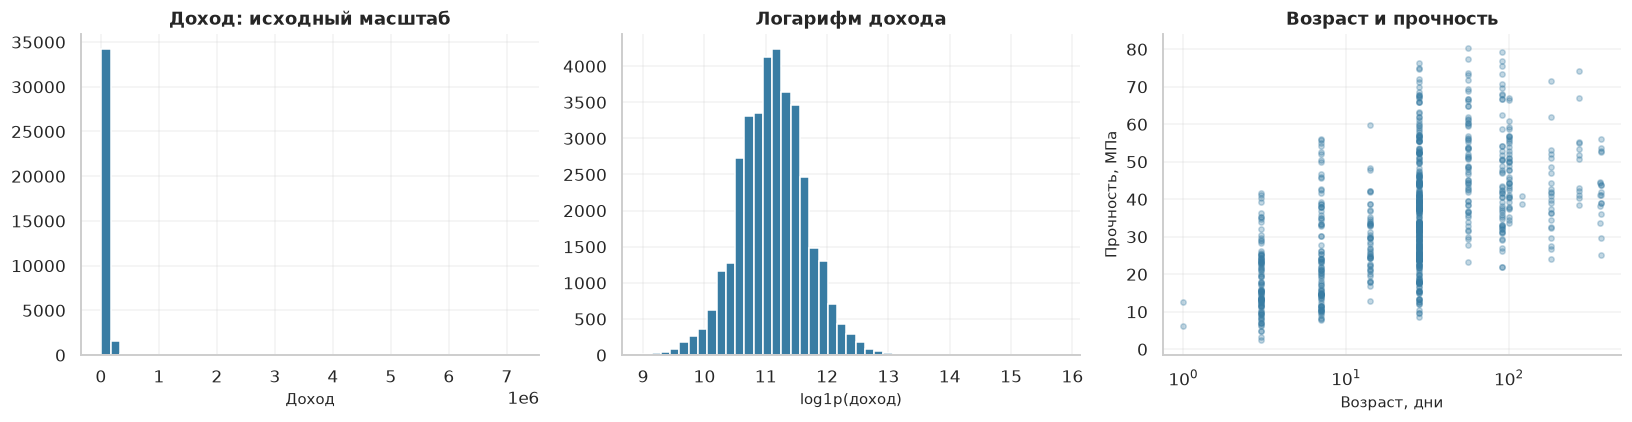

In [4]:
# EDA не обращается к отложенной выборке; справочные распределения строятся только на train.
c, r = tasks["classification"], tasks["regression"]
show_table(c["y_train"].value_counts().rename("count").to_frame().assign(
    fraction=c["y_train"].value_counts(normalize=True)))
show_table(r["X_train"].join(r["y_train"]).describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(c["X_train"]["person_income"], bins=45)
axes[0].set(title="Доход: исходный масштаб", xlabel="Доход")
axes[1].hist(np.log1p(c["X_train"]["person_income"].clip(lower=0)), bins=45)
axes[1].set(title="Логарифм дохода", xlabel="log1p(доход)")
axes[2].scatter(r["X_train"]["age"], r["y_train"], s=12, alpha=.3)
axes[2].set(xscale="log", xlabel="Возраст, дни", ylabel="Прочность, МПа", title="Возраст и прочность")
plt.tight_layout()
plt.show()

### Связи признаков и крайние значения

Покажу корреляции числовых признаков и крайние значения. Корреляция не доказывает
причинность; её полезно учитывать при интерпретации важностей. Наблюдения не удаляю
по результатам просмотра: сохраняю протокол №1–4 и проверяю регуляризацию леса.

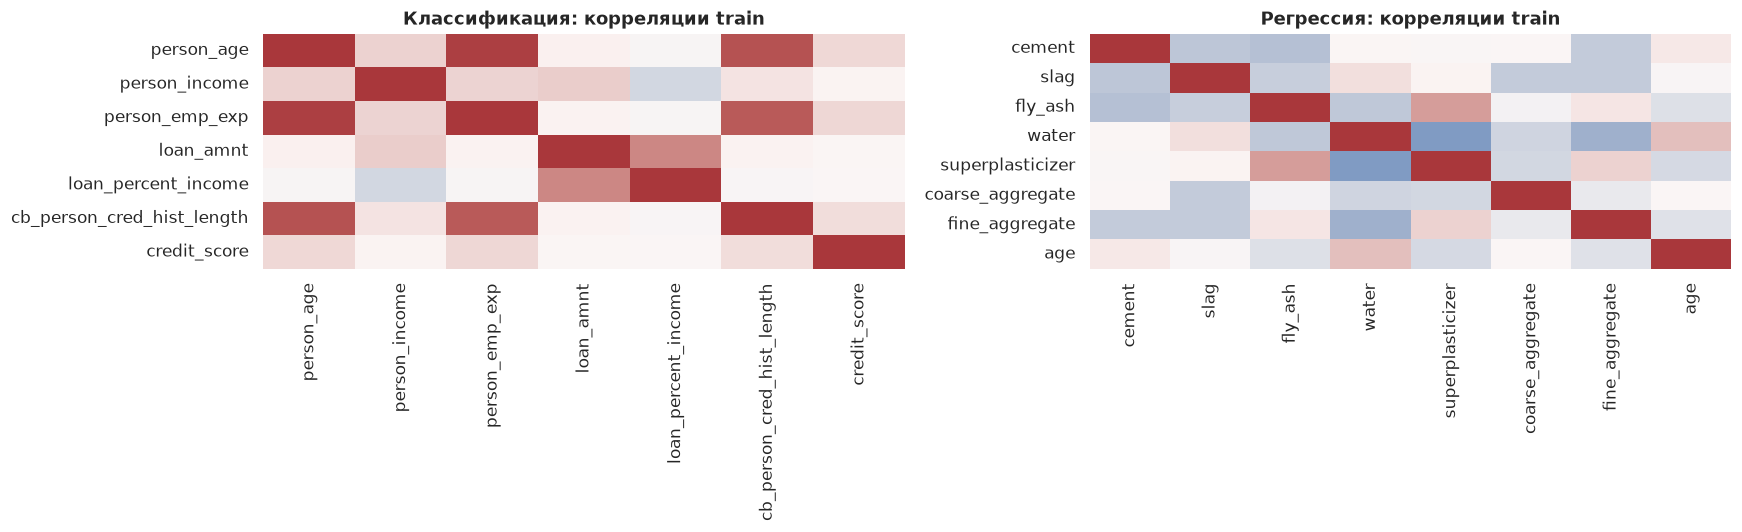

,0.000000,0.010000,0.500000,0.990000,1.000000
person_age,20.0000,21.0000,26.0000,48.0000,144.0000
person_income,8000.0000,17797.9900,67081.0000,274873.8100,7200766.0000
person_emp_exp,0.0000,0.0000,4.0000,26.0000,125.0000
loan_amnt,500.0000,1170.9800,8000.0000,28251.3900,35000.0000
loan_percent_income,0.0000,0.0200,0.1200,0.4000,0.6600
cb_person_cred_hist_length,2.0000,2.0000,4.0000,17.0000,30.0000
credit_score,390.0000,497.0000,640.0000,723.0000,850.0000


In [5]:
# Дополнительная EDA использует только train; heatmap не включает test.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, task in zip(axes, tasks):
    numeric = tasks[task]["X_train"].select_dtypes(include="number")
    sns.heatmap(numeric.corr(), ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1, cbar=False)
    ax.set_title(TASK_NAMES[task] + ": корреляции train")
plt.tight_layout()
plt.show()
show_table(c["X_train"].select_dtypes(include="number").quantile([0, .01, .5, .99, 1]).T,
           "Кредитные признаки: min, 1%, медиана, 99%, max")

### Вывод по данным и протокол исследования

Дисбаланс одобрений обосновывает F1, precision/recall и AP. Группировка бетона по семи
компонентам без возраста проверяет обобщение на **новые рецептуры**, а не только на
новый возраст знакомой смеси. Близкие, но не одинаковые рецептуры могут оставаться зависимыми.

Порядок эксперимента фиксирую заранее: baseline → отдельные гипотезы → совместный
поиск скорости/числа деревьев, глубины, подвыборки и представления → перенос параметров
в собственные модели → анализ. Test не участвует в подборе параметров, порога и seed.
Автоматическое `n_iter_no_change` sklearn отключено: его внутренний случайный validation
не учитывает группы рецептур. Число итераций выбираю по нашей общей групповой CV.

## 2. Создание бейзлайна и оценка качества

Для обеих задач фиксирую **100 деревьев, learning_rate=0.1, max_depth=3,
min_samples_leaf=1, subsample=1.0**. Числовые признаки не масштабирую, категории —
полный one-hot с игнорированием неизвестных уровней. Пропуски: медиана / мода train.

Использую обычные `GradientBoostingClassifier/Regressor`. Настройки зафиксированного
sklearn показаны в результатах; устаревающий параметр `criterion` не передаю.
Для скалярного градиента без весов Friedman MSE и SSE имеют одинаковый порядок
выигрышей разбиений. Равные выигрыши и численная арифметика могут давать разные деревья.

Dummy предсказывает наиболее частый класс / медиану прочности. Время относится к полному
Pipeline, включает преобразования, не включает поиск по CV и измеряется одним запуском.

In [6]:
# Подготовка данных и отчёт одинаковы для sklearn и собственной модели.
def baseline_params(task):
    """Параметры фиксируются до подбора, одинаковая сложность для двух задач."""
    return dict(n_estimators=100, learning_rate=0.1, max_depth=3,
                min_samples_leaf=1, subsample=1.0)


def sklearn_model(task, **params):
    cls = GradientBoostingClassifier if task == "classification" else GradientBoostingRegressor
    # Friedman MSE и обычный SSE ранжируют пороги одинаково для скалярных остатков.
    return cls(random_state=SEED, n_iter_no_change=None,
               loss="log_loss" if task == "classification" else "squared_error", **params)



def make_pipeline(X, task, mode="raw", estimator=None):
    if mode not in ("raw", "scaled", "log", "engineered"):
        raise ValueError(f"Неизвестное представление {mode}")
    categorical = [column for column in CATEGORICAL if column in X]
    numeric = [column for column in X if column not in categorical]
    if mode == "engineered":
        numeric += (["employment_age_ratio", "credit_history_age_ratio"] if task == "classification"
                    else ["binder", "water_binder_ratio", "aggregate_binder_ratio"])
    steps = [("impute", SimpleImputer(strategy="median"))]
    if mode == "scaled":
        steps.append(("scale", StandardScaler()))
    transforms = [("numeric", Pipeline(steps), numeric)]
    if categorical:
        transforms.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical))
    return Pipeline([
        ("features", TaskFeatures(task, mode)),
        ("preprocess", ColumnTransformer(transforms, sparse_threshold=0)),
        ("model", sklearn_model(task, **baseline_params(task)) if estimator is None else estimator),
    ])

records, fitted, predictions, complexity = [], {}, {}, []

def fit_evaluate(task, name, model, mode):
    """Обучаю на полном train; test используется для отчётной оценки."""
    print(f"Обучение {task}: {name}", flush=True)
    t = tasks[task]
    started = perf_counter()
    model.fit(t["X_train"], t["y_train"])
    fit_seconds = perf_counter() - started
    started = perf_counter()
    if task == "classification":
        probabilities = model.predict_proba(t["X_test"])
        prediction = model.classes_[probabilities.argmax(axis=1)]
        proba = probabilities[:, 1]
    else:
        prediction, proba = model.predict(t["X_test"]), None
    predict_seconds = perf_counter() - started
    estimator = model.named_steps["model"]
    scores = evaluate(task, t["y_test"], prediction, proba)
    records.append(dict(lab=5, algorithm="Dummy" if name == "dummy" else
                        ("GradientBoostingClassifier" if task == "classification" else "GradientBoostingRegressor"),
                        model=name, implementation="custom" if name.startswith("custom") else "sklearn",
                        stage="dummy" if name == "dummy" else name.split("_")[1], task=task,
                        dataset=t["spec"]["name"], target=t["spec"]["target"],
                        feature_set=",".join(t["X_train"].columns), dataset_sha=t["spec"]["sha256"],
                        split_sha=t["split_sha"], protocol_id=t["spec"]["protocol_id"],
                        n_train=len(t["X_train"]), n_test=len(t["X_test"]),
                        fit_seconds=fit_seconds, predict_seconds=predict_seconds,
                        representation=mode, estimator=type(estimator).__name__, **scores))
    fitted[task, name] = model
    predictions[task, name] = (prediction, proba)
    pd.DataFrame({"row_id": t["X_test"].index, "truth": t["y_test"].to_numpy(),
                  "prediction": prediction, **({"probability": proba} if proba is not None else {})}).to_csv(
        RESULTS / f"predictions_{task}_{name}.csv", index=False)
    if name != "dummy":
        train_pred = model.predict(t["X_train"])
        train_score = (f1_score(t["y_train"], train_pred) if task == "classification"
                       else mean_absolute_error(t["y_train"], train_pred))
        trees = (list(estimator.estimators_.ravel()) if isinstance(estimator.estimators_, np.ndarray)
                 else estimator.estimators_)
        complexity.append(dict(task=task, model=name, n_estimators=len(trees),
            depth_mean=float(np.mean([tree.get_depth() for tree in trees])),
            total_nodes=sum(tree.node_count_ if hasattr(tree, "node_count_") else tree.tree_.node_count
                            for tree in trees), train_score=train_score))
    return scores

def show_metrics(frame):
    for task in tasks:
        cols = (["model", "f1", "precision", "recall", "balanced_accuracy", "accuracy", "roc_auc", "average_precision"]
                if task == "classification" else ["model", "mae", "rmse", "r2"])
        show_table(frame.loc[frame.task == task, cols].reset_index(drop=True), TASK_NAMES[task])

### Качество исходных моделей

Перед улучшениями получу CV-оценки baseline на трёх фолдах и результаты на фиксированном
holdout. Все последующие варианты проверяются на train; test не передаётся в поиск параметров.
В таблице сложности train F1 желательно сравнивать с CV F1, а train MAE — с CV MAE:
разрыв помогает заметить переобучение ансамбля.

In [7]:
# Исходные параметры фиксируются до проверки гипотез.
base_models, hypothesis_records = {}, []
for task, t in tasks.items():
    base_models[task] = make_pipeline(t["X_train"], task, "raw")
    scores = cross_val_score(base_models[task], t["X_train"], t["y_train"],
                             cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
    hypothesis_records.append(dict(task=task, mode="raw", cv_mean=float(scores.mean()),
                                   cv_std=float(scores.std()), folds=scores.tolist()))
    dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
    fit_evaluate(task, "dummy", make_pipeline(t["X_train"], task, "raw", dummy), "raw")
    fit_evaluate(task, "sklearn_baseline", clone(base_models[task]), "raw")
show_table(pd.DataFrame(hypothesis_records).drop(columns="folds"), "Исходные CV-оценки (F1 / отрицательная MAE)")
show_metrics(pd.DataFrame(records))
show_table(pd.DataFrame(complexity), "Сложность и качество на train")

Обучение classification: dummy


Обучение classification: sklearn_baseline


Обучение regression: dummy


Обучение regression: sklearn_baseline


Задача,Признаки,Среднее CV,Разброс CV
Классификация,raw,0.7287,0.0039
Регрессия,raw,-4.6682,0.2003


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7373,0.8696,0.6400,0.8063,0.8987,0.9538,0.8772


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,5.1012,7.0129,0.8476


Задача,Модель,Деревьев,Средняя глубина,Всего узлов,Качество train
Классификация,sklearn · исходная,100,3.0000,1406,0.7368
Регрессия,sklearn · исходная,100,3.0000,1476,2.7117


### Вывод по исходному бейзлайну

Сравню с Dummy и разрывом train/CV. Train-score и CV-score относятся к одной
основной метрике, а не к внутренней функции потерь. В регрессии преобразую
отрицательную MAE из sklearn в привычную положительную ошибку в МПа.

In [8]:
# Краткие выводы строятся из реально полученных метрик этого запуска.
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    m = pd.DataFrame(records).query("task == @task").set_index("model")
    h = next(row for row in hypothesis_records if row["task"] == task)
    cv_value = h["cv_mean"] if task == "classification" else -h["cv_mean"]
    train_value = next(row["train_score"] for row in complexity if row["task"] == task)
    display(Markdown(f"**{TASK_NAMES[task]}:** Dummy **{m.loc['dummy', metric]:.5f}**, "
        f"исходный бустинг **{m.loc['sklearn_baseline', metric]:.5f}** на test. "
        f"Train {'F1' if task == 'classification' else 'MAE'} = **{train_value:.5f}**, "
        f"CV = **{cv_value:.5f}**. {'Больше' if task == 'classification' else 'Меньше'} — лучше."))

**Классификация:** Dummy **0.00000**, исходный бустинг **0.73733** на test. Train F1 = **0.73684**, CV = **0.72872**. Больше — лучше.

**Регрессия:** Dummy **14.52331**, исходный бустинг **5.10118** на test. Train MAE = **2.71166**, CV = **4.66824**. Меньше — лучше.

## 3. Улучшение бейзлайна

Сначала формулирую гипотезы, затем проверяю их на общих трёх train-CV-фолдах.

| Гипотеза | Проверка | Ожидание |
|:--|:--|:--|
| H1. Масштабирование | raw против scaled при baseline | Почти нет эффекта: порядок значений сохраняется |
| H2. Log | log1p дохода / возраста против raw | Проверить поведение порогов между наблюдениями |
| H3. Новые признаки | engineered против log | Отношения компонентов упрощают нужные разбиения |
| H4. Скорость и число деревьев | η=0.05/0.15; M=25/50/100/200 | Маленький шаг требует больше итераций |
| H5. Глубина | 2/3 в совместном поиске | Баланс взаимодействий и переобучения |
| H6. Минимум в листе | 1/5/15 для заявок, 1/3/10 для бетона | Сглаживание локальных поправок |
| H7. Подвыборка | 0.7/1.0 в совместном поиске | Возможна регуляризация ценой шума градиента |

`engineered` включает log и отношения стажа/возраста и истории/возраста для заявок;
для бетона — вяжущие, вода/вяжущие, заполнители/вяжущие. Цель не используется.
Все знаменатели защищены от нуля. Порог класса остаётся 0,5.

### H1–H3: отдельная проверка предобработки

Меняю только представление, остальные параметры baseline сохраняю.
Запишу оценки каждого фолда, среднее и стандартное отклонение.
В CV-таблицах **F1 / отрицательная MAE: больше — лучше**. Стандартное отклонение
по трём фолдам описывает разброс и не является доверительным интервалом.

In [9]:
# Изолированно проверю преобразования при исходных параметрах бустинга.
for task, t in tasks.items():
    for mode in ["scaled", "log", "engineered"]:
        scores = cross_val_score(make_pipeline(t["X_train"], task, mode), t["X_train"], t["y_train"],
                                 cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
        hypothesis_records.append(dict(task=task, mode=mode, cv_mean=float(scores.mean()),
                                       cv_std=float(scores.std()), folds=scores.tolist()))
hypotheses = pd.DataFrame(hypothesis_records)
hypotheses.to_json(RESULTS / "hypotheses.json", orient="records", indent=2)
show_table(hypotheses.drop(columns="folds"), "F1 / отрицательная MAE: больше — лучше")

Задача,Признаки,Среднее CV,Разброс CV
Классификация,raw,0.7287,0.0039
Регрессия,raw,-4.6682,0.2003
Классификация,scaled,0.7287,0.0039
Классификация,log,0.7287,0.0039
Классификация,engineered,0.7291,0.0060
Регрессия,scaled,-4.6882,0.2155
Регрессия,log,-4.6681,0.2005
Регрессия,engineered,-4.1341,0.1947


### H6: изолированная проверка размера листа

Проверю размер листа при исходных признаках и остальных параметрах baseline.
Это позволяет отделить эффект сглаживания от совместного изменения других настроек.
Эти варианты также войдут в итоговый набор кандидатов на улучшенный бейзлайн.

In [10]:
# Каждая конфигурация проходит полный Pipeline на тех же CV-фолдах.
leaf_records = []
for task, t in tasks.items():
    for leaf in ([1, 5, 15] if task == "classification" else [1, 3, 10]):
        if leaf == 1:
            scores = np.array(next(h["folds"] for h in hypothesis_records if h["task"] == task and h["mode"] == "raw"))
        else:
            params = baseline_params(task) | {"min_samples_leaf": leaf}
            model = make_pipeline(t["X_train"], task, "raw", sklearn_model(task, **params))
            scores = cross_val_score(model, t["X_train"], t["y_train"], cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
        leaf_records.append(dict(task=task, min_samples_leaf=leaf, cv_mean=float(scores.mean()),
                                 cv_std=float(scores.std()), folds=scores.tolist()))
pd.DataFrame(leaf_records).to_json(RESULTS / "leaf_cv.json", orient="records", indent=2)
show_table(pd.DataFrame(leaf_records).drop(columns="folds"))

Задача,Минимум в листе,Среднее CV,Разброс CV
Классификация,1,0.7287,0.0039
Классификация,5,0.7285,0.0048
Классификация,15,0.7283,0.0040
Регрессия,1,-4.6682,0.2003
Регрессия,3,-4.6077,0.2198
Регрессия,10,-4.6146,0.1563


### H4–H5–H7: совместный поиск и выбор числа итераций

Проверю полное произведение `raw/engineered × learning_rate=0.05/0.15 × max_depth=2/3
× subsample=0.7/1.0` с листом от 5 объектов для заявок и от 3 для бетона.
Это **16 траекторий на задачу**, каждая по 200 деревьев на трёх фолдах.
Добавлю исходную траекторию `raw, η=0.1, depth=3, leaf=1, subsample=1`.
Оценю каждую траекторию на **25, 50, 100, 200** деревьях: 68 конфигураций на задачу.
Первые M деревьев берутся из одного `staged_predict`; модель не обучается заново для каждого M.

Внутри каждого фолда преобразования обучаются отдельно для каждого представления.
Одну и ту же подготовленную матрицу этого фолда можно использовать для разных параметров
дерева: статистики validation не участвуют в её построении.
Дополнительно сохраняю train/CV основную метрику и log-loss / MSE по стадиям.

In [11]:
# Предобработка кэшируется только внутри конкретных train-fold и представления.
STAGES = [25, 50, 100, 200]
trajectory_records, trajectory_configs, fold_cache = [], {}, {}
for task, t in tasks.items():
    trajectory_configs[task] = [dict(mode=mode, learning_rate=rate, max_depth=depth,
        min_samples_leaf=5 if task == "classification" else 3, subsample=fraction)
        for mode, rate, depth, fraction in product(["raw", "engineered"], [.05, .15], [2, 3], [.7, 1.])]
    trajectory_configs[task].append(dict(mode="raw", **{k: v for k, v in baseline_params(task).items() if k != "n_estimators"}))
    for mode in ["raw", "engineered"]:
        for fold, (a, b) in enumerate(t["cv"]):
            prep = clone(make_pipeline(t["X_train"], task, mode)[:-1])
            Xt = prep.fit_transform(t["X_train"].iloc[a], t["y_train"].iloc[a])
            Xv = prep.transform(t["X_train"].iloc[b])
            fold_cache[task, mode, fold] = Xt, Xv
    for config_id, config in enumerate(trajectory_configs[task]):
        print(f"{TASK_NAMES[task]}: траектория {config_id + 1}/17", flush=True)
        mode = config["mode"]
        params = {k: v for k, v in config.items() if k != "mode"}
        for fold, (a, b) in enumerate(t["cv"]):
            Xt, Xv = fold_cache[task, mode, fold]
            model = sklearn_model(task, n_estimators=max(STAGES), **params)
            started = perf_counter()
            model.fit(Xt, t["y_train"].iloc[a])
            fit_seconds = perf_counter() - started
            iterator = model.staged_predict_proba if task == "classification" else model.staged_predict
            for stage, (train_out, valid_out) in enumerate(zip(iterator(Xt), iterator(Xv)), start=1):
                if stage not in STAGES:
                    continue
                if task == "classification":
                    train_score = f1_score(t["y_train"].iloc[a], train_out.argmax(axis=1))
                    score = f1_score(t["y_train"].iloc[b], valid_out.argmax(axis=1))
                    train_loss, valid_loss = log_loss(t["y_train"].iloc[a], train_out), log_loss(t["y_train"].iloc[b], valid_out)
                else:
                    train_score = -mean_absolute_error(t["y_train"].iloc[a], train_out)
                    score = -mean_absolute_error(t["y_train"].iloc[b], valid_out)
                    train_loss, valid_loss = mean_squared_error(t["y_train"].iloc[a], train_out), mean_squared_error(t["y_train"].iloc[b], valid_out)
                trajectory_records.append(dict(task=task, config_id=config_id, fold=fold,
                    n_estimators=stage, **config, cv_score=score, train_score=train_score,
                    train_loss=train_loss, validation_loss=valid_loss, trajectory_fit_seconds=fit_seconds))
    pd.DataFrame(trajectory_records).query("task == @task").to_csv(RESULTS / f"trajectory_{task}.csv", index=False)
trajectories = pd.DataFrame(trajectory_records)
cv_summary = trajectories.groupby(["task", "config_id", "n_estimators"], as_index=False).agg(
    cv_mean=("cv_score", "mean"), cv_std=("cv_score", lambda s: s.std(ddof=0)),
    train_mean=("train_score", "mean"), validation_loss=("validation_loss", "mean"))
show_table(cv_summary.sort_values(["task", "cv_mean"], ascending=[True, False]).groupby("task").head(10))

Классификация: траектория 1/17


Классификация: траектория 2/17


Классификация: траектория 3/17


Классификация: траектория 4/17


Классификация: траектория 5/17


Классификация: траектория 6/17


... (25 outputs left out)

Регрессия: траектория 15/17


Регрессия: траектория 16/17


Регрессия: траектория 17/17


,Задача,config_id,Деревьев,Среднее CV,Разброс CV,train_mean,Потери validation
63,Классификация,15,200,0.7646,0.0088,0.7994,0.1994
31,Классификация,7,200,0.7612,0.0105,0.7982,0.1991
59,Классификация,14,200,0.7609,0.0088,0.7954,0.2010
27,Классификация,6,200,0.7604,0.0104,0.7971,0.2007
67,Классификация,16,200,0.7503,0.0083,0.7749,0.2051
19,Классификация,4,200,0.7472,0.0070,0.7626,0.2122
55,Классификация,13,200,0.7456,0.0055,0.7575,0.2136
58,Классификация,14,100,0.7455,0.0079,0.7629,0.2089
62,Классификация,15,100,0.7443,0.0096,0.7625,0.2082
23,Классификация,5,200,0.7443,0.0057,0.7596,0.2126


### Итоговый выбор по train-CV

Объединю траектории с проверенными представлениями baseline и изолированными размерами листа.
Выбираю максимум среднего CV-score; при точном равенстве — меньше деревьев, затем
меньшую глубину, затем более ранний идентификатор кандидата. Baseline включён явно,
поэтому выбранный CV-score не ниже исходного **на тех же фолдах**.
Это не гарантирует выигрыша на test: повторный отбор по CV создаёт оптимизм.

In [12]:
# Сохраняются все кандидаты и оценки каждого фолда, а не только победитель.
selected, candidate_tables = {}, {}
for task in tasks:
    candidates = []
    for row in cv_summary.query("task == @task").itertuples():
        config = trajectory_configs[task][row.config_id]
        scores = trajectories.query("task == @task and config_id == @row.config_id and n_estimators == @row.n_estimators").sort_values("fold").cv_score.to_numpy()
        candidates.append(dict(source="trajectory", mode=config["mode"], n_estimators=int(row.n_estimators),
            **{k: v for k, v in config.items() if k != "mode"}, cv_mean=row.cv_mean, cv_std=row.cv_std,
            **{f"fold_{i}": float(score) for i, score in enumerate(scores)}))
    for h in hypothesis_records:
        if h["task"] == task:
            candidates.append(dict(source="representation", mode=h["mode"], **baseline_params(task),
                cv_mean=h["cv_mean"], cv_std=h["cv_std"], **{f"fold_{i}": v for i, v in enumerate(h["folds"])}))
    for h in leaf_records:
        if h["task"] == task:
            candidates.append(dict(source="leaf", mode="raw", **(baseline_params(task) | {"min_samples_leaf": h["min_samples_leaf"]}),
                cv_mean=h["cv_mean"], cv_std=h["cv_std"], **{f"fold_{i}": v for i, v in enumerate(h["folds"])}))
    table = pd.DataFrame(candidates).rename_axis("candidate_id").reset_index()
    table = table.sort_values(["cv_mean", "n_estimators", "max_depth", "candidate_id"], ascending=[False, True, True, True], kind="stable")
    best = table.iloc[0]
    params = {k: int(best[k]) if k in ["n_estimators", "max_depth", "min_samples_leaf"] else float(best[k]) for k in baseline_params(task)}
    selected[task] = dict(mode=str(best["mode"]), params=params, cv_score=float(best.cv_mean),
        cv_std=float(best.cv_std), folds=[float(best[f"fold_{i}"]) for i in range(3)], source=str(best.source))
    candidate_tables[task] = table
    table.to_csv(RESULTS / f"cv_{task}.csv", index=False)
    show_table(table.head(10), TASK_NAMES[task] + ": 10 лучших кандидатов")
(RESULTS / "selected.json").write_text(json.dumps(selected, ensure_ascii=False, indent=2))
print(json.dumps(selected, ensure_ascii=False, indent=2))

,candidate_id,source,Признаки,Деревьев,Скорость обучения,Предел глубины,Минимум в листе,Доля строк,Среднее CV,Разброс CV,fold_0,fold_1,fold_2
63,63,trajectory,engineered,200,0.1500,3,5,1.0000,0.7646,0.0088,0.7521,0.7707,0.7711
31,31,trajectory,raw,200,0.1500,3,5,1.0000,0.7612,0.0105,0.7470,0.7720,0.7647
59,59,trajectory,engineered,200,0.1500,3,5,0.7000,0.7609,0.0088,0.7484,0.7678,0.7664
27,27,trajectory,raw,200,0.1500,3,5,0.7000,0.7604,0.0104,0.7457,0.7683,0.7672
67,67,trajectory,raw,200,0.1000,3,1,1.0000,0.7503,0.0083,0.7386,0.7556,0.7568
19,19,trajectory,raw,200,0.1500,2,5,0.7000,0.7472,0.0070,0.7373,0.7529,0.7513
55,55,trajectory,engineered,200,0.1500,2,5,1.0000,0.7456,0.0055,0.7381,0.7515,0.7471
58,58,trajectory,engineered,100,0.1500,3,5,0.7000,0.7455,0.0079,0.7344,0.7511,0.7512
62,62,trajectory,engineered,100,0.1500,3,5,1.0000,0.7443,0.0096,0.7316,0.7549,0.7464
23,23,trajectory,raw,200,0.1500,2,5,1.0000,0.7443,0.0057,0.7363,0.7473,0.7492


,candidate_id,source,Признаки,Деревьев,Скорость обучения,Предел глубины,Минимум в листе,Доля строк,Среднее CV,Разброс CV,fold_0,fold_1,fold_2
63,63,trajectory,engineered,200,0.1500,3,3,1.0000,-3.8671,0.1277,-4.0390,-3.7334,-3.8289
59,59,trajectory,engineered,200,0.1500,3,3,0.7000,-3.9061,0.1432,-4.0443,-3.7088,-3.9651
62,62,trajectory,engineered,100,0.1500,3,3,1.0000,-4.0120,0.1679,-4.2491,-3.8824,-3.9045
43,43,trajectory,engineered,200,0.0500,3,3,0.7000,-4.0354,0.2007,-4.3191,-3.9024,-3.8847
58,58,trajectory,engineered,100,0.1500,3,3,0.7000,-4.0576,0.2021,-4.3283,-3.8428,-4.0015
51,51,trajectory,engineered,200,0.1500,2,3,0.7000,-4.0863,0.1240,-4.2221,-3.9223,-4.1144
55,55,trajectory,engineered,200,0.1500,2,3,1.0000,-4.0908,0.0993,-4.2153,-3.9723,-4.0849
47,47,trajectory,engineered,200,0.0500,3,3,1.0000,-4.1236,0.2492,-4.4412,-4.0969,-3.8326
71,71,representation,engineered,100,0.1000,3,1,1.0000,-4.1341,0.1947,-4.4035,-4.0482,-3.9505
31,31,trajectory,raw,200,0.1500,3,3,1.0000,-4.2709,0.2061,-4.4266,-4.4063,-3.9796


{
  "classification": {
    "mode": "engineered",
    "params": {
      "n_estimators": 200,
      "learning_rate": 0.15,
      "max_depth": 3,
      "min_samples_leaf": 5,
      "subsample": 1.0
    },
    "cv_score": 0.7646453658779278,
    "cv_std": 0.00884947874764953,
    "folds": [
      0.7521331945889699,
      0.7706688824262568,
      0.7711340206185567
    ],
    "source": "trajectory"
  },
  "regression": {
    "mode": "engineered",
    "params": {
      "n_estimators": 200,
      "learning_rate": 0.15,
      "max_depth": 3,
      "min_samples_leaf": 3,
      "subsample": 1.0
    },
    "cv_score": -3.8671108750406997,
    "cv_std": 0.12765174933152526,
    "folds": [
      -4.039014470842999,
      -3.733416863389268,
      -3.8289012908898323
    ],
    "source": "trajectory"
  }
}


### Кривые обучения: скорость, число деревьев и переобучение

Для выбранных в совместном поиске представления, глубины и подвыборки покажу обе
скорости обучения. Размер листа фиксирован как в поиске. Линии — средние трёх фолдов,
полосы — ± одно стандартное отклонение validation. Основная метрика и потери могут
иметь разные оптимумы: выбор производится по F1 / MAE, а не по картинке потерь.

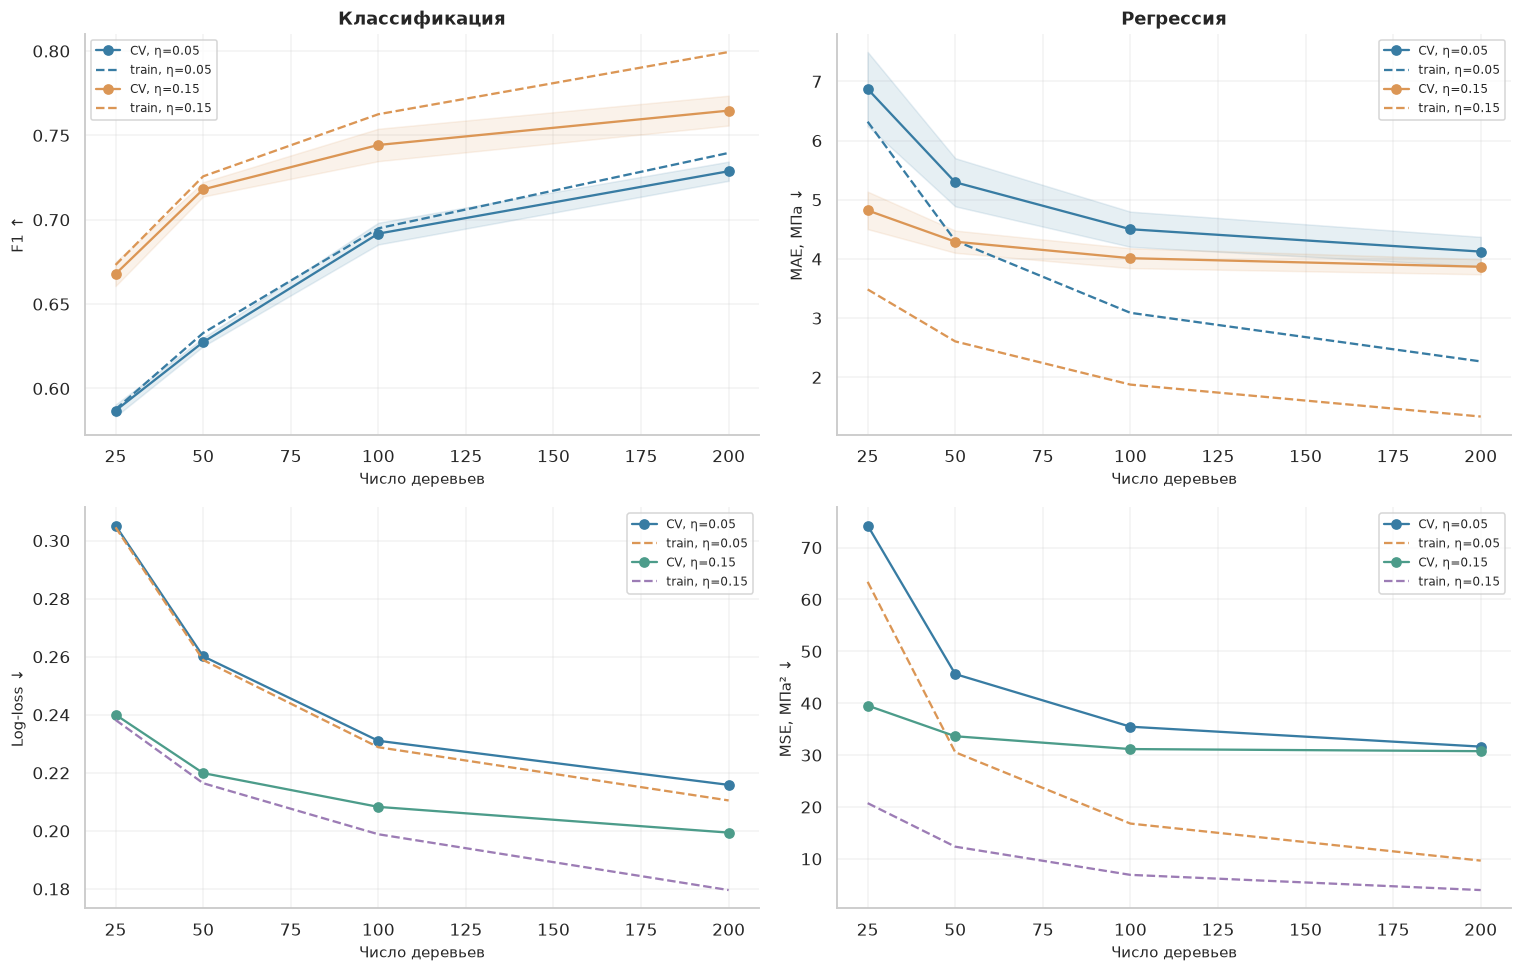

In [13]:
# Срезы удерживают остальные параметры; кривые строятся только по train-CV.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for column, task in enumerate(tasks):
    best_path = cv_summary.query("task == @task").sort_values("cv_mean", ascending=False).iloc[0]
    config = trajectory_configs[task][int(best_path.config_id)]
    part = trajectories[(trajectories.task == task) & (trajectories["mode"] == config["mode"])
        & (trajectories.max_depth == config["max_depth"]) & (trajectories.subsample == config["subsample"])
        & (trajectories.min_samples_leaf == config["min_samples_leaf"])]
    sign = 1 if task == "classification" else -1
    for rate, frame in part.groupby("learning_rate"):
        group = frame.groupby("n_estimators")
        x = group.cv_score.mean().index.to_numpy()
        mean, std = sign * group.cv_score.mean().to_numpy(), group.cv_score.std(ddof=0).to_numpy()
        line, = axes[0, column].plot(x, mean, marker="o", label=f"CV, η={rate}")
        axes[0, column].fill_between(x, mean-std, mean+std, color=line.get_color(), alpha=.12)
        axes[0, column].plot(x, sign*group.train_score.mean(), linestyle="--", color=line.get_color(), label=f"train, η={rate}")
        axes[1, column].plot(x, group.validation_loss.mean(), marker="o", label=f"CV, η={rate}")
        axes[1, column].plot(x, group.train_loss.mean(), linestyle="--", label=f"train, η={rate}")
    axes[0, column].set(title=TASK_NAMES[task], xlabel="Число деревьев", ylabel="F1 ↑" if sign == 1 else "MAE, МПа ↓")
    axes[1, column].set(xlabel="Число деревьев", ylabel="Log-loss ↓" if sign == 1 else "MSE, МПа² ↓")
    for ax in axes[:, column]: ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Результаты проверки гипотез

Для H1–H3 и H6 приведу изолированные разности. Для H4, H5 и H7 рассчитаю среднюю
**парную** разность конфигураций совместного поиска: при сравнении меняется один
параметр, остальные, включая M и фолды, совпадают. Средний эффект зависит от сетки;
он не устанавливает, какой параметр единолично обеспечил улучшение победившей модели.

In [14]:
# Все разности выражены в F1 / отрицательной MAE: положительное значение лучше.
hypothesis_rows = []
for task in tasks:
    h = hypotheses.query("task == @task").set_index("mode")
    for left, right, label in [("scaled", "raw", "H1 · scaled − raw"), ("log", "raw", "H2 · log − raw"), ("engineered", "log", "H3 · engineered − log")]:
        hypothesis_rows.append(dict(task=task, experiment=label, delta=h.loc[left,"cv_mean"]-h.loc[right,"cv_mean"]))
    part = trajectories.query("task == @task and config_id < 16")
    keys = ["fold", "n_estimators", "mode", "learning_rate", "max_depth", "min_samples_leaf", "subsample"]
    for parameter, low, high, label in [("learning_rate", .05, .15, "H4 · η=0.15 − 0.05"),
        ("max_depth", 2, 3, "H5 · depth=3 − 2"), ("subsample", 1., .7, "H7 · subsample=0.7 − 1")]:
        pivot = part.pivot(index=[k for k in keys if k != parameter], columns=parameter, values="cv_score")
        hypothesis_rows.append(dict(task=task, experiment=label, delta=float((pivot[high]-pivot[low]).mean())))
    leaf = pd.DataFrame(leaf_records).query("task == @task").set_index("min_samples_leaf")
    for size in leaf.index[leaf.index != 1]:
        hypothesis_rows.append(dict(task=task, experiment=f"H6 · leaf={size} − 1", delta=leaf.loc[size,"cv_mean"]-leaf.loc[1,"cv_mean"]))
    hypothesis_rows.append(dict(task=task, experiment="Выбранный вариант − baseline", delta=selected[task]["cv_score"]-h.loc["raw","cv_mean"]))
hypothesis_summary = pd.DataFrame(hypothesis_rows)
hypothesis_summary.to_csv(RESULTS / "hypothesis_summary.csv", index=False)
show_table(hypothesis_summary)
for task in tasks:
    sign = 1 if task == "classification" else -1
    h = hypotheses.query("task == @task").set_index("mode")
    display(Markdown(f"**{TASK_NAMES[task]}:** исходный CV = **{sign*h.loc['raw','cv_mean']:.5f}**, "
        f"выбранный CV = **{sign*selected[task]['cv_score']:.5f}**. Настройки: "
        f"`{selected[task]['mode']}`, `{selected[task]['params']}`. "
        "Отсутствие улучшения отдельной гипотезой также является результатом исследования."))

Задача,Проверка,Изменение
Классификация,H1 · scaled − raw,0.0000
Классификация,H2 · log − raw,0.0000
Классификация,H3 · engineered − log,0.0004
Классификация,H4 · η=0.15 − 0.05,0.0659
Классификация,H5 · depth=3 − 2,0.0250
Классификация,H7 · subsample=0.7 − 1,0.0034
Классификация,H6 · leaf=5 − 1,-0.0002
Классификация,H6 · leaf=15 − 1,-0.0005
Классификация,Выбранный вариант − baseline,0.0359
Регрессия,H1 · scaled − raw,-0.0199


**Классификация:** исходный CV = **0.72872**, выбранный CV = **0.76465**. Настройки: `engineered`, `{'n_estimators': 200, 'learning_rate': 0.15, 'max_depth': 3, 'min_samples_leaf': 5, 'subsample': 1.0}`. Отсутствие улучшения отдельной гипотезой также является результатом исследования.

**Регрессия:** исходный CV = **4.66824**, выбранный CV = **3.86711**. Настройки: `engineered`, `{'n_estimators': 200, 'learning_rate': 0.15, 'max_depth': 3, 'min_samples_leaf': 3, 'subsample': 1.0}`. Отсутствие улучшения отдельной гипотезой также является результатом исследования.

### Улучшенный бейзлайн sklearn на test

Параметры и представления уже выбраны по CV. Обучу окончательные модели на полном train
и сравню с исходными. Улучшенный здесь означает результат процедуры улучшения по CV:
фактическое изменение на test может иметь любой знак.

In [15]:
# Конфигурации выбраны по CV; test используется только для отчёта.
for task in tasks:
    fit_evaluate(task, "sklearn_improved", make_pipeline(tasks[task]["X_train"], task, selected[task]["mode"],
                     sklearn_model(task, **selected[task]["params"])), selected[task]["mode"])
show_metrics(pd.DataFrame(records))
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    group = pd.DataFrame(records).query("task == @task").set_index("model")
    old, new = group.loc["sklearn_baseline", metric], group.loc["sklearn_improved", metric]
    display(Markdown(f"**{TASK_NAMES[task]}:** исходная {'F1' if task == 'classification' else 'MAE'} "
                     f"**{old:.5f}**, улучшенная **{new:.5f}**, изменение **{new-old:+.5f}**. "
                     f"Выигрыш на CV не гарантирует такой же выигрыш на test."))

Обучение classification: sklearn_improved


Обучение regression: sklearn_improved


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7373,0.8696,0.6400,0.8063,0.8987,0.9538,0.8772
sklearn · улучшенная,0.7679,0.8571,0.6955,0.8312,0.9066,0.9612,0.8939


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,5.1012,7.0129,0.8476
sklearn · улучшенная,4.0606,5.6713,0.9003


**Классификация:** исходная F1 **0.73733**, улучшенная **0.76787**, изменение **+0.03054**. Выигрыш на CV не гарантирует такой же выигрыш на test.

**Регрессия:** исходная MAE **5.10118**, улучшенная **4.06058**, изменение **-1.04060**. Выигрыш на CV не гарантирует такой же выигрыш на test.

## 4. Самостоятельная реализация градиентного бустинга

Градиенты, начальная константа, подвыборки, последовательное обновление прогноза,
Newton-значения листьев, sigmoid и staged-прогнозы реализованы на **NumPy**.
Базовое дерево — собственная CART из №3, без готовых деревьев и ансамблей sklearn.
Sklearn используется для estimator API, проверки входов, Pipeline и отчётных метрик.

Ниже показаны обе части полностью: собственное дерево и код бустинга.
В регрессии дерево обучается на остатках, в классификации — на $y-p$,
после чего средние в листьях заменяются отношением градиента к кривизне log-loss.
Shrinkage применяется **один раз** при прибавлении дерева.

Вход приводится к float32, суммы и потери считаются в float64. Sigmoid вычисляется без
переполнения, log-loss — через `logaddexp`, нулевой знаменатель Newton защищён.
Поддерживаются бинарные метки произвольного типа и одноцелевая регрессия.

**Отличия от sklearn:** порядок разрешения равноценных разбиений, погрешности накопленных сумм,
генератор и состав подвыборок. При `subsample=1` случайный seed в своей модели ничего
не меняет; sklearn может менять порядок перебора равноценных признаков.
Сравниваю метрики и ответы на отдельных объектах, не ожидая идентичных деревьев.

### 4.1. Базовое CART на NumPy

Повторно использую [реализацию №3](../lab_3/src/decision_tree.py). Для полноты чтения
покажу её код в notebook: в каждом узле сортируются значения признака,
накопленные суммы позволяют оценить все допустимые пороги по SSE.
Лист хранит среднее; ограничение глубины и минимума в листе задаёт сложность.

In [16]:
# Собственный CART, готовое дерево sklearn не вызывается.
"""CART на NumPy: полный перебор порогов, Gini и squared_error.

sklearn используется только для интерфейса estimator и проверки входов.
Поиск разбиений, рост дерева, вероятности и прогноз реализованы самостоятельно.
"""

from numbers import Integral
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_is_fitted, validate_data


class _CART(BaseEstimator):
    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 min_impurity_decrease=0.0):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease

    def _validate_parameters(self):
        for name, lower in [("max_depth", 1), ("min_samples_split", 2), ("min_samples_leaf", 1)]:
            value = getattr(self, name)
            if name == "max_depth" and value is None:
                continue
            if isinstance(value, bool) or not isinstance(value, Integral) or value < lower:
                raise ValueError(f"{name} должен быть целым числом >= {lower}")
        if not np.isfinite(self.min_impurity_decrease) or self.min_impurity_decrease < 0:
            raise ValueError("min_impurity_decrease должен быть конечным и >= 0")

    def _fit(self, X, y, classification):
        self._validate_parameters()
        X, y = validate_data(self, X, y, dtype=np.float32, y_numeric=not classification)
        if y.ndim != 1:
            raise ValueError("Поддерживается одна целевая переменная")
        self._classification = classification
        if classification:
            check_classification_targets(y)
            self.classes_, target = np.unique(y, return_inverse=True)
            self.n_classes_ = len(self.classes_)
            if self.class_weight not in (None, "balanced"):
                raise ValueError("Поддерживаются class_weight=None и balanced")
            counts = np.bincount(target, minlength=self.n_classes_)
            weights = np.ones(len(y)) if self.class_weight is None else len(y) / (self.n_classes_ * counts[target])
        else:
            # Центрирование уменьшает потерю точности при вычислении SSE.
            self.target_offset_ = float(np.mean(y))
            target = np.asarray(y, dtype=np.float64) - self.target_offset_
            weights = np.ones(len(y))
        self.nodes_ = []
        self.feature_importances_ = np.zeros(X.shape[1])
        self.max_depth_ = 0
        self.n_leaves_ = 0
        total_weight = weights.sum()
        # Стек вместо рекурсии позволяет строить и глубокие деревья.
        pending = [(np.arange(len(y)), 0, None, None)]
        while pending:
            indices, depth, parent, side = pending.pop()
            values, w = target[indices], weights[indices]
            mass = w.sum()
            if classification:
                histogram = np.bincount(values, weights=w, minlength=self.n_classes_)
                value = histogram / mass
                impurity = max(0.0, 1.0 - value @ value)
                parent_cost = mass * impurity
            else:
                mean = values.mean()
                value = mean + self.target_offset_
                parent_cost = float(np.sum((values - mean) ** 2))
                impurity = parent_cost / mass
            node = dict(feature=-1, threshold=np.nan, left=-1, right=-1, value=value,
                        n_samples=len(indices), impurity=impurity, depth=depth)
            node_id = len(self.nodes_)
            self.nodes_.append(node)
            if parent is not None:
                self.nodes_[parent][side] = node_id
            self.max_depth_ = max(self.max_depth_, depth)
            best = None
            best_cost = np.inf
            can_split = (len(indices) >= max(self.min_samples_split, 2 * self.min_samples_leaf)
                         and (self.max_depth is None or depth < self.max_depth)
                         and impurity > np.finfo(float).eps)
            if can_split:
                for feature in range(X.shape[1]):
                    order = np.argsort(X[indices, feature], kind="stable")
                    sorted_indices = indices[order]
                    x = X[sorted_indices, feature].astype(np.float64)
                    positions = np.arange(1, len(x))
                    # Почти равные float32-значения не образуют отдельный порог.
                    valid = ((x[1:] > x[:-1] + 1e-7)
                             & (positions >= self.min_samples_leaf)
                             & (len(x) - positions >= self.min_samples_leaf))
                    if not valid.any():
                        continue
                    ordered_target, ordered_w = target[sorted_indices], weights[sorted_indices]
                    if classification:
                        onehot = np.zeros((len(x), self.n_classes_))
                        onehot[np.arange(len(x)), ordered_target] = ordered_w
                        left_counts = np.cumsum(onehot, axis=0)[:-1]
                        right_counts = histogram - left_counts
                        left_mass = np.cumsum(ordered_w)[:-1]
                        right_mass = mass - left_mass
                        costs = (mass - (left_counts ** 2).sum(axis=1) / left_mass
                                 - (right_counts ** 2).sum(axis=1) / right_mass)
                    else:
                        cumulative = np.cumsum(ordered_target)[:-1]
                        cumulative2 = np.cumsum(ordered_target ** 2)[:-1]
                        total, total2 = ordered_target.sum(), np.sum(ordered_target ** 2)
                        costs = (cumulative2 - cumulative ** 2 / positions
                                 + total2 - cumulative2 - (total - cumulative) ** 2 / (len(x) - positions))
                    costs[~valid] = np.inf
                    cut = int(np.argmin(costs))
                    # При равенстве сохраняется первый признак и первый порог.
                    if costs[cut] < best_cost - 1e-12:
                        best_cost = float(costs[cut])
                        threshold = x[cut] / 2.0 + x[cut + 1] / 2.0
                        best = (feature, threshold, sorted_indices[:cut + 1], sorted_indices[cut + 1:])
            gain = 0.0 if best is None else max(0.0, parent_cost - best_cost)
            if best is None or gain / total_weight + 1e-15 < self.min_impurity_decrease:
                self.n_leaves_ += 1
                continue
            feature, threshold, left, right = best
            node.update(feature=feature, threshold=threshold)
            self.feature_importances_[feature] += gain
            pending.append((right, depth + 1, node_id, "right"))
            pending.append((left, depth + 1, node_id, "left"))
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        self.node_count_ = len(self.nodes_)
        return self

    def _values(self, X):
        check_is_fitted(self, "nodes_")
        X = validate_data(self, X, reset=False, dtype=np.float32)
        shape = (len(X), self.n_classes_) if self._classification else (len(X),)
        result = np.empty(shape)
        pending = [(0, np.arange(len(X)))]
        while pending:
            node_id, rows = pending.pop()
            if not len(rows):
                continue
            node = self.nodes_[node_id]
            if node["feature"] < 0:
                result[rows] = node["value"]
            else:
                goes_left = X[rows, node["feature"]] <= node["threshold"]
                pending.append((node["left"], rows[goes_left]))
                pending.append((node["right"], rows[~goes_left]))
        return result

    def get_depth(self):
        check_is_fitted(self, "nodes_")
        return self.max_depth_

    def get_n_leaves(self):
        check_is_fitted(self, "nodes_")
        return self.n_leaves_


class NumpyDecisionTreeClassifier(ClassifierMixin, _CART):
    """CART с Gini, вероятностями в листьях и необязательными весами классов."""

    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 min_impurity_decrease=0.0, class_weight=None):
        super().__init__(max_depth, min_samples_split, min_samples_leaf, min_impurity_decrease)
        self.class_weight = class_weight

    def fit(self, X, y):
        return self._fit(X, y, classification=True)

    def predict_proba(self, X):
        return self._values(X)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return self.classes_[probabilities.argmax(axis=1)]


class NumpyDecisionTreeRegressor(RegressorMixin, _CART):
    """CART с минимизацией SSE и средним целевой переменной в листе."""

    def fit(self, X, y):
        return self._fit(X, y, classification=False)

    def predict(self, X):
        return self._values(X)

### 4.2. Градиенты, Newton, подвыборки и прогноз ансамбля

Класс `_BoostingTree` добавляет получение идентификаторов листьев. `_GradientBoosting`
выполняет общий цикл; отдельные классы реализуют интерфейсы двух задач.
Список индексов подвыборки и история потерь сохраняются для аудита.
Код совпадает с [src/gradient_boosting.py](src/gradient_boosting.py).

In [17]:
# Полный код ансамбля на NumPy.
"""Градиентный бустинг на NumPy поверх собственной CART из лабораторной №3.

Готовые деревья и ансамбли sklearn не используются. Бинарная log-loss и
квадратичная ошибка, shrinkage, subsampling без возвращения, staged-прогнозы.
"""

from numbers import Integral, Real
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_is_fitted, validate_data
from lab_3.src.decision_tree import NumpyDecisionTreeRegressor


def sigmoid(raw):
    """Устойчивая sigmoid: exp получает только неположительные аргументы."""
    raw = np.asarray(raw, dtype=float)
    z = np.exp(-np.abs(raw))
    return np.where(raw >= 0, 1 / (1 + z), z / (1 + z))


class _BoostingTree(NumpyDecisionTreeRegressor):
    def apply(self, X):
        """Идентификаторы листьев для обновления Newton; обход собственного CART."""
        check_is_fitted(self, "nodes_")
        X = validate_data(self, X, reset=False, dtype=np.float32)
        leaves = np.empty(len(X), dtype=int)
        pending = [(0, np.arange(len(X)))]
        while pending:
            node_id, rows = pending.pop()
            if not len(rows):
                continue
            node = self.nodes_[node_id]
            if node["feature"] < 0:
                leaves[rows] = node_id
            else:
                left = X[rows, node["feature"]] <= node["threshold"]
                pending.append((node["left"], rows[left]))
                pending.append((node["right"], rows[~left]))
        return leaves


class _GradientBoosting(BaseEstimator):
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3,
                 min_samples_leaf=1, subsample=1.0, random_state=42):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.subsample = subsample
        self.random_state = random_state

    def _validate_parameters(self):
        for name in ["n_estimators", "max_depth", "min_samples_leaf"]:
            value = getattr(self, name)
            if isinstance(value, bool) or not isinstance(value, Integral) or value < 1:
                raise ValueError(f"{name} должен быть целым >= 1")
        for name in ["learning_rate", "subsample"]:
            value = getattr(self, name)
            if (isinstance(value, bool) or not isinstance(value, Real)
                    or not np.isfinite(value) or value <= 0):
                raise ValueError(f"{name} должен быть конечным положительным числом")
        if self.subsample > 1:
            raise ValueError("subsample должен принадлежать (0, 1]")
        if self.random_state is not None and (isinstance(self.random_state, bool)
                or not isinstance(self.random_state, Integral) or self.random_state < 0):
            raise ValueError("random_state должен быть целым >= 0 или None")

    def _fit(self, X, y, classification):
        self._validate_parameters()
        X, y = validate_data(self, X, y, dtype=np.float32, y_numeric=not classification)
        if y.ndim != 1:
            raise ValueError("Поддерживается одна целевая переменная")
        self._classification = classification
        if classification:
            check_classification_targets(y)
            self.classes_, encoded = np.unique(y, return_inverse=True)
            if len(self.classes_) != 2:
                raise ValueError("Поддерживается только бинарная классификация с двумя классами")
            target = encoded.astype(float)
            prior = np.clip(target.mean(), np.finfo(float).eps, 1 - np.finfo(float).eps)
            self.init_ = float(np.log(prior / (1 - prior)))
        else:
            target = np.asarray(y, dtype=float)
            self.init_ = float(target.mean())
        raw = np.full(len(target), self.init_)
        rng = np.random.default_rng(self.random_state)
        self.estimators_, self.estimators_samples_, self.train_score_ = [], [], []
        self.n_samples_subsample_ = max(1, int(self.subsample * len(target)))
        for _ in range(self.n_estimators):
            # Остатки считаются по ансамблю предыдущего шага, до добавления дерева.
            probability = sigmoid(raw) if classification else None
            gradient = target - (probability if classification else raw)
            rows = (rng.choice(len(target), self.n_samples_subsample_, replace=False)
                    if self.subsample < 1 else np.arange(len(target)))
            tree = _BoostingTree(max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf)
            tree.fit(X[rows], gradient[rows])
            if classification:
                # Дерево строит регионы по SSE градиента; значения листьев заменяет Newton.
                leaves = tree.apply(X[rows])
                for leaf in np.unique(leaves):
                    indices = rows[leaves == leaf]
                    numerator = gradient[indices].sum()
                    denominator = np.sum(probability[indices] * (1 - probability[indices]))
                    tree.nodes_[int(leaf)]["value"] = (float(numerator / denominator)
                        if denominator > np.finfo(float).eps else 0.0)
            raw += self.learning_rate * tree.predict(X)
            self.estimators_.append(tree)
            self.estimators_samples_.append(rows)
            loss = (np.mean(np.logaddexp(0, raw) - target * raw) if classification
                    else np.mean((target - raw) ** 2))
            self.train_score_.append(float(loss))
        self.train_score_ = np.asarray(self.train_score_)
        self.n_estimators_ = len(self.estimators_)
        return self

    def _staged_raw_predict(self, X):
        check_is_fitted(self, "estimators_")
        X = validate_data(self, X, reset=False, dtype=np.float32)
        raw = np.full(len(X), self.init_)
        for tree in self.estimators_:
            raw += self.learning_rate * tree.predict(X)
            yield raw.copy()

    def _raw_predict(self, X):
        # Последний элемент staged; копии защищают историю от изменения in-place.
        for raw in self._staged_raw_predict(X):
            pass
        return raw


class NumpyGradientBoostingClassifier(ClassifierMixin, _GradientBoosting):
    """Бинарная log-loss, градиент y-p и Newton-обновление каждого листа."""

    def fit(self, X, y):
        return self._fit(X, y, classification=True)

    def decision_function(self, X):
        return self._raw_predict(X)

    def predict_proba(self, X):
        p = sigmoid(self.decision_function(X))
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return self.classes_[(self.decision_function(X) > 0).astype(int)]

    def staged_predict_proba(self, X):
        for raw in self._staged_raw_predict(X):
            p = sigmoid(raw)
            yield np.column_stack([1 - p, p])

    def staged_predict(self, X):
        for raw in self._staged_raw_predict(X):
            yield self.classes_[(raw > 0).astype(int)]


class NumpyGradientBoostingRegressor(RegressorMixin, _GradientBoosting):
    """Квадратичная ошибка: начальное среднее и деревья остатков y-F."""

    def fit(self, X, y):
        return self._fit(X, y, classification=False)

    def predict(self, X):
        return self._raw_predict(X)

    def staged_predict(self, X):
        yield from self._staged_raw_predict(X)

### 4.3. Ручная проверка одного шага и математические свойства

Для регрессии $y=(1,1,5,5)$, $F_0=3$, остатки $(-2,-2,2,2)$.
Пень делит признаки между 1 и 2; при $\eta=0.25$ прогноз $(2.5,2.5,3.5,3.5)$.
Для классификации $y=(0,0,1,1)$: $p_0=0.5$, градиент $(-0.5,-0.5,0.5,0.5)$,
Newton-листья $(-2,+2)$, при $\eta=0.1$ log-odds $(-0.2,-0.2,0.2,0.2)$.

Проверю эти равенства, нормировку вероятностей, соответствие последней стадии прогнозу
и отсутствие повторов при подвыборке. Отдельные pytest-проверки сравнивают несколько
итераций со sklearn на данных с однозначными разбиениями, повторный fit, clone,
произвольные метки, постоянную цель, сдвиг цели и некорректные параметры.

In [18]:
# Проверки имеют аналитически известный ответ, а не только сравнивают две реализации.
X_demo = np.arange(4).reshape(-1, 1)
r_demo = NumpyGradientBoostingRegressor(n_estimators=1, max_depth=1, learning_rate=.25).fit(X_demo, [1,1,5,5])
c_demo = NumpyGradientBoostingClassifier(n_estimators=1, max_depth=1, learning_rate=.1).fit(X_demo, [0,0,1,1])
np.testing.assert_allclose(r_demo.predict(X_demo), [2.5,2.5,3.5,3.5])
np.testing.assert_allclose(c_demo.decision_function(X_demo), [-.2,-.2,.2,.2])
np.testing.assert_allclose(c_demo.predict_proba(X_demo).sum(axis=1), 1)
np.testing.assert_allclose(list(c_demo.staged_predict_proba(X_demo))[-1], c_demo.predict_proba(X_demo))
sub_demo = NumpyGradientBoostingRegressor(n_estimators=3, subsample=.75).fit(X_demo, [1,1,5,5])
assert all(len(s) == len(np.unique(s)) == 3 for s in sub_demo.estimators_samples_)
show_table(pd.DataFrame({"x": X_demo[:,0], "Прогноз регрессии": r_demo.predict(X_demo),
    "Log-odds": c_demo.decision_function(X_demo), "P(класс 1)": c_demo.predict_proba(X_demo)[:,1]}))
print("Ручной шаг, вероятности, staged-прогноз и подвыборка проверены.")

x,Прогноз регрессии,Log-odds,P(класс 1)
0,2.5000,-0.2000,0.4502
1,2.5000,-0.2000,0.4502
2,3.5000,0.2000,0.5498
3,3.5000,0.2000,0.5498


Ручной шаг, вероятности, staged-прогноз и подвыборка проверены.


### 4.4. Исходные собственные модели

Обучу собственные классификатор и регрессор на полном train, сохранив исходные
100 деревьев, η=0.1, глубину 3, лист от 1 и все строки на каждом шаге.
Предобработка та же, что у исходного sklearn. Сравню все выбранные метрики.

In [19]:
# Train не сокращается для собственной реализации.
custom_classes = {"classification": NumpyGradientBoostingClassifier, "regression": NumpyGradientBoostingRegressor}
for task, t in tasks.items():
    custom = custom_classes[task](random_state=SEED, **baseline_params(task))
    fit_evaluate(task, "custom_baseline", make_pipeline(t["X_train"], task, "raw", custom), "raw")
show_metrics(pd.DataFrame(records))
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    m = pd.DataFrame(records).query("task == @task").set_index("model")
    display(Markdown(f"**{TASK_NAMES[task]}:** исходная своя = **{m.loc['custom_baseline',metric]:.5f}**, "
        f"исходная sklearn = **{m.loc['sklearn_baseline',metric]:.5f}**, "
        f"своя минус sklearn = **{m.loc['custom_baseline',metric]-m.loc['sklearn_baseline',metric]:+.5f}**."))

Обучение classification: custom_baseline


Обучение regression: custom_baseline


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7373,0.8696,0.6400,0.8063,0.8987,0.9538,0.8772
sklearn · улучшенная,0.7679,0.8571,0.6955,0.8312,0.9066,0.9612,0.8939
своя · исходная,0.7373,0.8696,0.6400,0.8063,0.8987,0.9538,0.8772


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,5.1012,7.0129,0.8476
sklearn · улучшенная,4.0606,5.6713,0.9003
своя · исходная,5.0903,6.9856,0.8488


**Классификация:** исходная своя = **0.73733**, исходная sklearn = **0.73733**, своя минус sklearn = **+0.00000**.

**Регрессия:** исходная своя = **5.09030**, исходная sklearn = **5.10118**, своя минус sklearn = **-0.01088**.

### 4.5. Перенос техник улучшенного бейзлайна

Перенесу выбранные по sklearn-CV представление, M, η, глубину, минимум в листе
и долю строк в собственные модели **без повторного подбора**. Это проверяет
переносимость улучшений; самостоятельная реализация могла бы иметь другой CV-оптимум.
Выбор гиперпараметров по test не выполняется.

In [20]:
# Параметры и представления берутся из selected, обучение выполняется на полном train.
for task, t in tasks.items():
    s = selected[task]
    custom = custom_classes[task](random_state=SEED, **s["params"])
    fit_evaluate(task, "custom_improved", make_pipeline(t["X_train"], task, s["mode"], custom), s["mode"])
show_metrics(pd.DataFrame(records))
metrics = pd.DataFrame(records)
metrics.to_csv(RESULTS / "metrics.csv", index=False)
pd.DataFrame(complexity).to_csv(RESULTS / "complexity.csv", index=False)

Обучение classification: custom_improved


Обучение regression: custom_improved


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7373,0.8696,0.6400,0.8063,0.8987,0.9538,0.8772
sklearn · улучшенная,0.7679,0.8571,0.6955,0.8312,0.9066,0.9612,0.8939
своя · исходная,0.7373,0.8696,0.6400,0.8063,0.8987,0.9538,0.8772
своя · улучшенная,0.7679,0.8571,0.6955,0.8312,0.9066,0.9612,0.8939


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,5.1012,7.0129,0.8476
sklearn · улучшенная,4.0606,5.6713,0.9003
своя · исходная,5.0903,6.9856,0.8488
своя · улучшенная,4.0836,5.7015,0.8993


### Совпадение прогнозов и сложность ансамблей

Измерю долю различных классов и абсолютные разности вероятностей/прогнозов до и после
улучшений. На одних метриках близкие значения могут скрывать разные ошибки на отдельных
объектах. Средняя глубина и число узлов помогают объяснить затраты своей реализации.

In [21]:
# Фактические расхождения прогнозов и затраты полного Pipeline.
agreement_rows = []
for task in tasks:
    for stage in ["baseline", "improved"]:
        a, pa = predictions[task, "custom_"+stage]
        b, pb = predictions[task, "sklearn_"+stage]
        row = dict(task=task, stage=stage, mean_abs_prediction_difference=float(np.mean(np.abs(a-b))),
                   max_abs_prediction_difference=float(np.max(np.abs(a-b))))
        if task == "classification":
            row.update(disagreement=float(np.mean(a != b)), mean_abs_probability_difference=float(np.mean(np.abs(pa-pb))))
        agreement_rows.append(row)
(RESULTS / "agreement.json").write_text(json.dumps(agreement_rows, ensure_ascii=False, indent=2))
show_table(pd.DataFrame(agreement_rows))
show_table(pd.DataFrame(complexity), "Сложность и train-качество")
show_table(metrics[["task","model","fit_seconds","predict_seconds"]], "Время полного Pipeline, один запуск")

Задача,Вариант,mean_abs_prediction_difference,max_abs_prediction_difference,disagreement,mean_abs_probability_difference
Классификация,baseline,0.0000,0.0000,0.0000,0.0000
Классификация,improved,0.0000,0.0000,0.0000,0.0000
Регрессия,baseline,0.0143,0.8635,—,—
Регрессия,improved,0.0439,1.0733,—,—


Задача,Модель,Деревьев,Средняя глубина,Всего узлов,Качество train
Классификация,sklearn · исходная,100,3.0000,1406,0.7368
Регрессия,sklearn · исходная,100,3.0000,1476,2.7117
Классификация,sklearn · улучшенная,200,3.0000,2864,0.7874
Регрессия,sklearn · улучшенная,200,3.0000,2738,1.6067
Классификация,своя · исходная,100,3.0000,1392,0.7368
Регрессия,своя · исходная,100,3.0000,1476,2.7117
Классификация,своя · улучшенная,200,3.0000,2852,0.7874
Регрессия,своя · улучшенная,200,3.0000,2738,1.6067


Задача,Модель,"Обучение, с","Прогноз, с"
Классификация,Dummy,0.0394,0.0071
Классификация,sklearn · исходная,3.4880,0.0185
Регрессия,Dummy,0.0025,0.0011
Регрессия,sklearn · исходная,0.0810,0.0017
Классификация,sklearn · улучшенная,8.3477,0.0237
Регрессия,sklearn · улучшенная,0.1997,0.0030
Классификация,своя · исходная,9.9842,0.0420
Регрессия,своя · исходная,0.2259,0.0094
Классификация,своя · улучшенная,23.0410,0.0732
Регрессия,своя · улучшенная,0.5894,0.0183


## 5. Дополнительный анализ и сравнение результатов

### Аудит подвыборок и история потерь

Для каждой собственной модели проверю размер и уникальность подвыборок, число деревьев
и совпадение последней стадии с итоговым прогнозом. История потерь считается на **всём train**,
включая строки вне текущей подвыборки. При subsample<1 монотонное уменьшение train-loss
на каждой итерации не гарантируется. Для log-loss Newton — приближённый шаг.

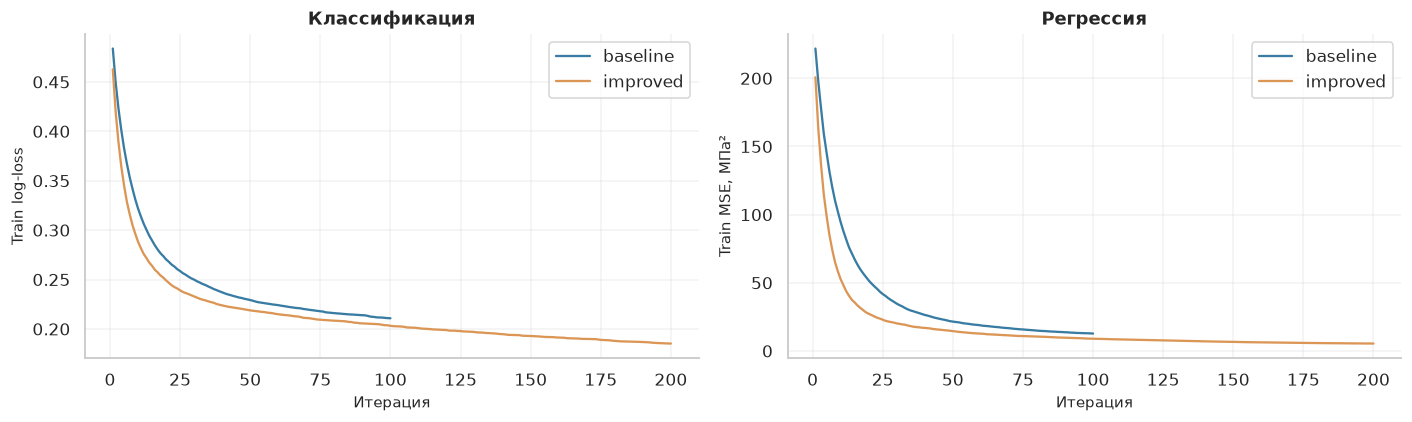

Задача,Вариант,Деревьев,Доля строк,rows_min,rows_max,all_rows_unique,train_loss_first,train_loss_last,loss_increases
Классификация,baseline,100,1.0000,36000,36000,True,0.4837,0.2108,0
Классификация,improved,200,1.0000,36000,36000,True,0.4627,0.1852,0
Регрессия,baseline,100,1.0000,799,799,True,221.8319,12.7336,0
Регрессия,improved,200,1.0000,799,799,True,200.7404,5.3983,0


In [22]:
# Аудит механизма подвыборки; все проверки опираются на фактически обученные модели.
audit_rows, loss_records = [], []
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for ax, task in zip(axes, tasks):
    t = tasks[task]
    for stage in ["baseline", "improved"]:
        pipe = fitted[task, "custom_"+stage]
        model = pipe.named_steps["model"]
        counts = np.array([len(s) for s in model.estimators_samples_])
        unique = np.array([len(np.unique(s)) for s in model.estimators_samples_])
        assert np.array_equal(counts, unique)
        Xt = pipe[:-1].transform(t["X_test"])
        np.testing.assert_allclose(list(model.staged_predict(Xt))[-1], model.predict(Xt))
        audit_rows.append(dict(task=task, stage=stage, n_estimators=model.n_estimators_,
            subsample=model.subsample, rows_min=int(counts.min()), rows_max=int(counts.max()),
            all_rows_unique=bool(np.array_equal(counts,unique)), train_loss_first=model.train_score_[0],
            train_loss_last=model.train_score_[-1], loss_increases=int(np.sum(np.diff(model.train_score_) > 1e-12))))
        loss_records.extend(dict(task=task, stage=stage, iteration=i+1, loss=float(v)) for i,v in enumerate(model.train_score_))
        ax.plot(np.arange(1,model.n_estimators_+1), model.train_score_, label=stage)
    ax.set(title=TASK_NAMES[task], xlabel="Итерация", ylabel="Train log-loss" if task == "classification" else "Train MSE, МПа²")
    ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(audit_rows).to_csv(RESULTS / "subsample_audit.csv", index=False)
pd.DataFrame(loss_records).to_csv(RESULTS / "train_loss.csv", index=False)
show_table(pd.DataFrame(audit_rows))

### Устойчивость к random_state

Для уже выбранного улучшенного sklearn повторю общую CV с seed **7, 21, 42**.
Меняется только seed модели; строки, рецептуры и фолды сохраняются.
Для 42 использую уже вычисленные оценки победителя. Лучший seed не выбираю.
При subsample=1 различия могут происходить только из-за равноценных разбиений sklearn.
Это чувствительность к случайности модели, а не интервал неопределённости нового train/test.

In [23]:
# Контроль устойчивости использует только train-CV.
seed_records = []
for task,t in tasks.items():
    s = selected[task]
    for seed in [7,21,42]:
        if seed == 42:
            scores = np.array(s["folds"])
        else:
            model = sklearn_model(task, **s["params"]).set_params(random_state=seed)
            pipe = make_pipeline(t["X_train"],task,s["mode"],model)
            scores = cross_val_score(pipe,t["X_train"],t["y_train"],cv=t["cv"],scoring=scoring[task],n_jobs=1,error_score="raise")
        seed_records.append(dict(task=task,seed=seed,cv_mean=float(scores.mean()),cv_std=float(scores.std()),folds=scores.tolist()))
pd.DataFrame(seed_records).to_json(RESULTS / "seed_cv.json",orient="records",indent=2)
show_table(pd.DataFrame(seed_records).drop(columns="folds"))

Задача,Seed,Среднее CV,Разброс CV
Классификация,7,0.7646,0.0088
Классификация,21,0.7646,0.0088
Классификация,42,0.7646,0.0088
Регрессия,7,-3.8861,0.1277
Регрессия,21,-3.8709,0.1386
Регрессия,42,-3.8671,0.1277


### Ошибки улучшенного sklearn

Покажу матрицу ошибок, ROC и precision–recall для заявок; затем прогнозы прочности,
остатки и абсолютные ошибки на новых рецептурах. Это анализ уже выбранной модели:
по этим графикам не меняю параметры или порог. Прямая на графике «факт–прогноз»
соответствует идеальному ответу, остаток — факт минус прогноз.

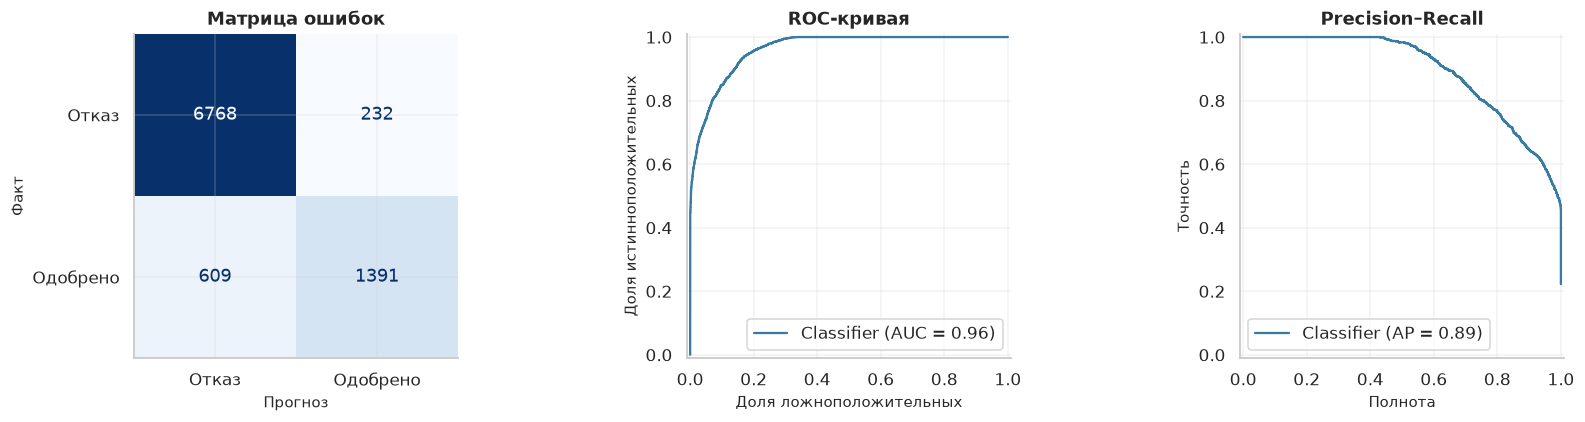

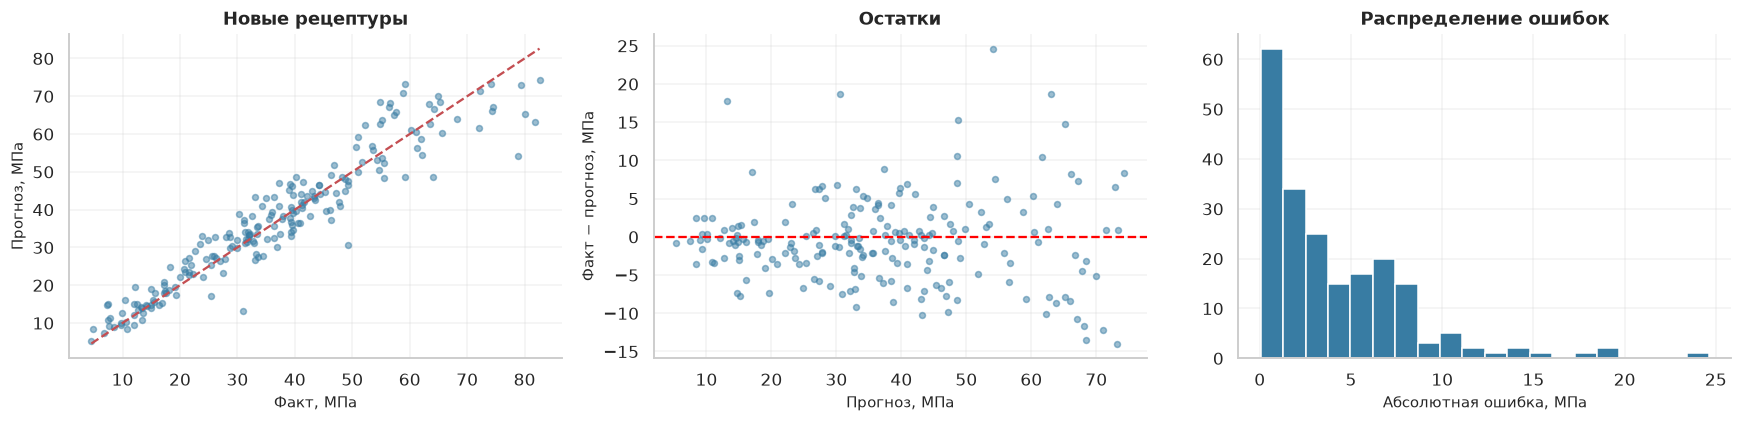

In [24]:
# Визуальная диагностика после выбора конфигурации; test не участвует в дальнейшем подборе.
y_c = tasks["classification"]["y_test"]
pred_c, prob_c = predictions["classification", "sklearn_improved"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_c, pred_c, ax=axes[0], colorbar=False, cmap="Blues", display_labels=["Отказ", "Одобрено"])
RocCurveDisplay.from_predictions(y_c, prob_c, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_c, prob_c, ax=axes[2])
axes[0].set(title="Матрица ошибок", xlabel="Прогноз", ylabel="Факт")
axes[1].set(title="ROC-кривая", xlabel="Доля ложноположительных", ylabel="Доля истинноположительных")
axes[2].set(title="Precision–Recall", xlabel="Полнота", ylabel="Точность")
plt.tight_layout()
plt.show()
y_r = tasks["regression"]["y_test"].to_numpy()
pred_r = predictions["regression", "sklearn_improved"][0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(y_r, pred_r, alpha=.5, s=15)
axes[0].plot([y_r.min(), y_r.max()], [y_r.min(), y_r.max()], "r--")
axes[0].set(xlabel="Факт, МПа", ylabel="Прогноз, МПа", title="Новые рецептуры")
axes[1].scatter(pred_r, y_r - pred_r, alpha=.5, s=15)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Прогноз, МПа", ylabel="Факт − прогноз, МПа", title="Остатки")
axes[2].hist(np.abs(y_r - pred_r), bins=20)
axes[2].set(xlabel="Абсолютная ошибка, МПа", title="Распределение ошибок")
plt.tight_layout()
plt.show()

### Какие ошибки остаются

Посчитаю FP/FN, среднюю ошибку по классам и MAE по диапазонам прочности.
Для небольших подгрупп оценка нестабильна; значения служат диагностикой.
Реальные одобрения в наборе не являются метками будущего дефолта клиента.

In [25]:
# Описываю ошибки на test после завершения отбора; таблицы не используются для настройки.
fp = int(np.sum((np.asarray(y_c)==0) & (pred_c==1)))
fn = int(np.sum((np.asarray(y_c)==1) & (pred_c==0)))
display(Markdown(f"**Классификация:** ошибочные одобрения FP = **{fp}**, "
                 f"пропущенные одобрения FN = **{fn}**. Изменение порога смещает этот баланс; "
                 "в работе он остаётся равным 0,5."))
error_table = pd.DataFrame({"truth":y_r, "prediction":pred_r, "absolute_error":np.abs(y_r-pred_r)})
error_table["Прочность"] = pd.cut(error_table.truth, [-np.inf,20,40,60,np.inf],
                                labels=["<20", "20–40", "40–60", ">60"])
show_table(error_table.groupby("Прочность", observed=True).agg(count=("truth","size"),
    mae=("absolute_error","mean"), mean_residual=("truth", lambda s: np.mean(s-error_table.loc[s.index,"prediction"]))))
display(Markdown(f"**Регрессия:** медиана абсолютной ошибки **{np.median(np.abs(y_r-pred_r)):.3f} МПа**, "
                 f"90-й процентиль **{np.quantile(np.abs(y_r-pred_r),.9):.3f} МПа**, "
                 f"максимум **{np.max(np.abs(y_r-pred_r)):.3f} МПа**."))

**Классификация:** ошибочные одобрения FP = **232**, пропущенные одобрения FN = **609**. Изменение порога смещает этот баланс; в работе он остаётся равным 0,5.

,Количество,"MAE, МПа ↓",mean_residual
Прочность,,,
<20,45,2.0964,-1.4158
20–40,82,3.8233,-1.2727
40–60,56,4.8142,-0.9115
>60,23,6.9145,5.5363


**Регрессия:** медиана абсолютной ошибки **2.819 МПа**, 90-й процентиль **8.401 МПа**, максимум **24.623 МПа**.

### Важности исходных признаков на CV-validation

Permutation importance показывает снижение F1 / увеличение MAE при перемешивании
одного исходного столбца. Обучу выбранный Pipeline только на train первого CV-фолда,
важность оценю на его validation, по **5 повторов**. Исходные столбцы перемешиваются
до расчёта отношений, поэтому зависимые созданные признаки пересчитываются согласованно.

Этот фолд уже участвовал в выборе конфигурации; важности — описательная диагностика.
Корреляции и зависимости могут распределять важность между столбцами.
Положительная важность не доказывает причинную связь. Test для отбора признаков не используется.

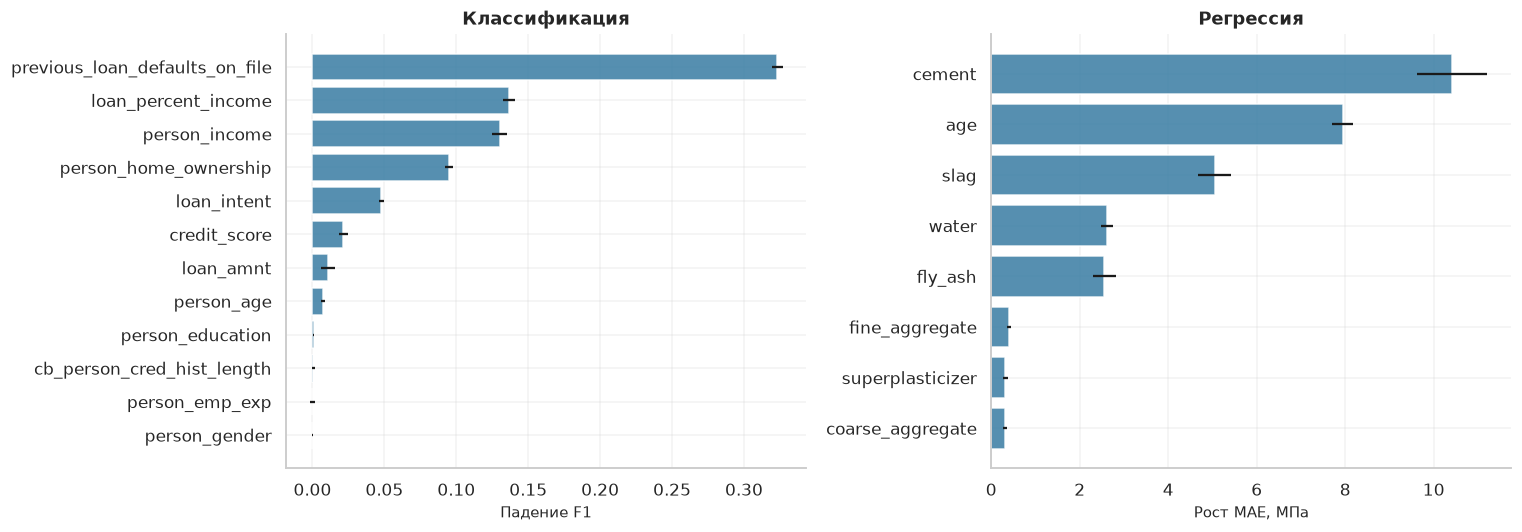

,Задача,feature,importance,std
11,Классификация,previous_loan_defaults_on_file,0.3232,0.0037
8,Классификация,loan_percent_income,0.1364,0.0041
3,Классификация,person_income,0.1304,0.0052
5,Классификация,person_home_ownership,0.0951,0.0028
7,Классификация,loan_intent,0.0479,0.0018
10,Классификация,credit_score,0.0215,0.0033
6,Классификация,loan_amnt,0.0110,0.0048
0,Классификация,person_age,0.0074,0.0012
2,Классификация,person_education,0.0008,0.0004
9,Классификация,cb_person_cred_hist_length,0.0005,0.0011


In [26]:
# Отдельная модель на train-fold; permutation importance считается на его validation.
importance_records=[]
fig, axes=plt.subplots(1,2,figsize=(14,5))
for ax,(task,t) in zip(axes,tasks.items()):
    a,b=t["cv"][0]; s=selected[task]
    model=make_pipeline(t["X_train"],task,s["mode"],sklearn_model(task,**s["params"]))
    model.fit(t["X_train"].iloc[a],t["y_train"].iloc[a])
    importance=permutation_importance(model,t["X_train"].iloc[b],t["y_train"].iloc[b],
        scoring=scoring[task],n_repeats=5,random_state=SEED,n_jobs=1)
    table=pd.DataFrame({"feature":t["X_train"].columns,"importance":importance.importances_mean,"std":importance.importances_std})
    importance_records.extend(dict(task=task,**row) for row in table.to_dict("records"))
    table=table.sort_values("importance")
    ax.barh(table.feature,table.importance,xerr=table["std"],alpha=.85)
    ax.set(title=TASK_NAMES[task],xlabel="Падение F1" if task=="classification" else "Рост MAE, МПа")
plt.tight_layout(); plt.show()
pd.DataFrame(importance_records).to_csv(RESULTS / "permutation_importances.csv",index=False)
show_table(pd.DataFrame(importance_records).sort_values(["task","importance"],ascending=[True,False]))

### Неопределённость разностей на test

Для улучшенный минус исходный sklearn и своя минус sklearn после улучшений посчитаю
парные percentile bootstrap-интервалы (500 повторов). Классификация ресэмплирует строки;
регрессия — **целые рецептуры** с возвращением, сохраняя все возраста выбранной смеси.
В каждом повторе сравниваются одни и те же выбранные объекты для двух моделей.

Интервал условен относительно уже обученных моделей и данного holdout. Он не учитывает
случайность обучения и множественный выбор гиперпараметров. Зависимость синтетических
кредитных объектов может занижать оценённую неопределённость. Если интервал пересекает ноль,
наблюдаемого изменения недостаточно для уверенного вывода о знаке эффекта.

In [27]:
# Парный bootstrap использует готовые test-прогнозы, без переобучения и подбора.
rng = np.random.default_rng(SEED)
interval_rows = []
for task, t in tasks.items():
    truth = t["y_test"].to_numpy()
    if task == "regression":
        group_lookup = t["split"].set_index("row_id").loc[t["X_test"].index,"group_id"].to_numpy()
        groups = np.unique(group_lookup)
        blocks = [np.flatnonzero(group_lookup==g) for g in groups]
    for left,right,label in [("sklearn_improved","sklearn_baseline","Улучшение sklearn"),
                             ("custom_improved","sklearn_improved","Своя минус sklearn после улучшений")]:
        p_left, p_right = predictions[task,left][0], predictions[task,right][0]
        score_fn = f1_score if task=="classification" else mean_absolute_error
        deltas=[]
        for _ in range(500):
            rows = (rng.integers(0,len(truth),len(truth)) if task=="classification" else
                    np.concatenate([blocks[i] for i in rng.integers(0,len(blocks),len(blocks))]))
            deltas.append(score_fn(truth[rows],p_left[rows])-score_fn(truth[rows],p_right[rows]))
        interval_rows.append(dict(task=task, comparison=label,
            delta=score_fn(truth,p_left)-score_fn(truth,p_right),
            lower_95=float(np.quantile(deltas,.025)), upper_95=float(np.quantile(deltas,.975))))
intervals = pd.DataFrame(interval_rows)
intervals.to_csv(RESULTS / "paired_bootstrap.csv", index=False)
show_table(intervals, "Разность F1 / MAE и условный 95% percentile-интервал")

Задача,Сравнение,Изменение,lower_95,upper_95
Классификация,Улучшение sklearn,0.0305,0.0197,0.0399
Классификация,Своя минус sklearn после улучшений,0.0000,0.0000,0.0000
Регрессия,Улучшение sklearn,-1.0406,-1.6432,-0.4841
Регрессия,Своя минус sklearn после улучшений,0.0230,0.0031,0.0526


### Все обязательные сравнения и результаты работ №1–5

Покажу четыре пары: улучшенный и исходный sklearn; своя и sklearn до улучшения;
своя и sklearn после улучшения; своя до и после переноса техник.
Затем сравню улучшенные sklearn всех пяти работ. Перед объединением проверю
идентичность источников, SHA данных и разбиений, цели и набора исходных признаков.

In [28]:
# Сравню варианты внутри работы, затем сравню улучшенные sklearn всех пяти работ.
comparison_rows, previous_rows = [], []
pairs = [("sklearn_improved", "sklearn_baseline", "Улучшение sklearn"),
         ("custom_baseline", "sklearn_baseline", "Своя и sklearn: исходные"),
         ("custom_improved", "sklearn_improved", "Своя и sklearn: улучшенные"),
         ("custom_improved", "custom_baseline", "Улучшение своей модели")]

for task in tasks:
    m = metrics[metrics.task == task].set_index("model")
    metric = "f1" if task == "classification" else "mae"
    for left, right, label in pairs:
        comparison_rows.append({"task": task, "comparison": label,
                                "metric": "F1" if metric == "f1" else "MAE, МПа",
                                "delta": m.loc[left, metric] - m.loc[right, metric]})
    for number in [1, 2, 3, 4, 5]:
        frame = metrics if number == 5 else pd.read_csv(ROOT / f"lab_{number}" / "results" / "metrics.csv")
        row = frame[(frame.task == task) & (frame.model == "sklearn_improved")].iloc[0]
        for field, expected in [("split_sha", tasks[task]["split_sha"]),
                                ("dataset_sha", tasks[task]["spec"]["sha256"]),
                                ("protocol_id", tasks[task]["spec"]["protocol_id"]),
                                ("feature_set", ",".join(tasks[task]["X_train"].columns)),
                                ("target", tasks[task]["spec"]["target"])]:
            assert row[field] == expected
        previous_rows.append({"lab": number, "task": task, "algorithm": row.algorithm,
                              "metric": "F1" if metric == "f1" else "MAE, МПа", "Значение": row[metric]})
show_table(pd.DataFrame(comparison_rows), "Изменение основных метрик")
show_table(pd.DataFrame(previous_rows), "Улучшенные sklearn из работ №1–5")
show_table(metrics[["task", "model", "fit_seconds", "predict_seconds"]].reset_index(drop=True), "Время всего Pipeline")
# Полные метрики нужны для автоматических итогов по всем алгоритмам.
all_results = pd.concat([pd.read_csv(ROOT/f"lab_{i}/results/metrics.csv") for i in range(1,6)],ignore_index=True)

Задача,Сравнение,Метрика,Изменение
Классификация,Улучшение sklearn,F1,0.0305
Классификация,Своя и sklearn: исходные,F1,0.0000
Классификация,Своя и sklearn: улучшенные,F1,0.0000
Классификация,Улучшение своей модели,F1,0.0305
Регрессия,Улучшение sklearn,"MAE, МПа",-1.0406
Регрессия,Своя и sklearn: исходные,"MAE, МПа",-0.0109
Регрессия,Своя и sklearn: улучшенные,"MAE, МПа",0.0230
Регрессия,Улучшение своей модели,"MAE, МПа",-1.0067


Работа,Задача,Алгоритм,Метрика,Значение
1,Классификация,KNN,F1,0.6960
2,Классификация,LogisticRegression,F1,0.7157
3,Классификация,DecisionTreeClassifier,F1,0.7376
4,Классификация,RandomForestClassifier,F1,0.7757
5,Классификация,GradientBoostingClassifier,F1,0.7679
1,Регрессия,KNN,"MAE, МПа",4.4187
2,Регрессия,LinearRegression,"MAE, МПа",4.8704
3,Регрессия,DecisionTreeRegressor,"MAE, МПа",4.4701
4,Регрессия,RandomForestRegressor,"MAE, МПа",3.9766
5,Регрессия,GradientBoostingRegressor,"MAE, МПа",4.0606


Задача,Модель,"Обучение, с","Прогноз, с"
Классификация,Dummy,0.0394,0.0071
Классификация,sklearn · исходная,3.4880,0.0185
Регрессия,Dummy,0.0025,0.0011
Регрессия,sklearn · исходная,0.0810,0.0017
Классификация,sklearn · улучшенная,8.3477,0.0237
Регрессия,sklearn · улучшенная,0.1997,0.0030
Классификация,своя · исходная,9.9842,0.0420
Регрессия,своя · исходная,0.2259,0.0094
Классификация,своя · улучшенная,23.0410,0.0732
Регрессия,своя · улучшенная,0.5894,0.0183


### Итоговые графики качества

На первом графике — четыре варианта бустинга, на втором — улучшенные модели sklearn
всех пяти работ. F1 и MAE рассматриваются отдельно. Между работами сравниваются
полные решения, поэтому предобработка и созданные признаки могут различаться.

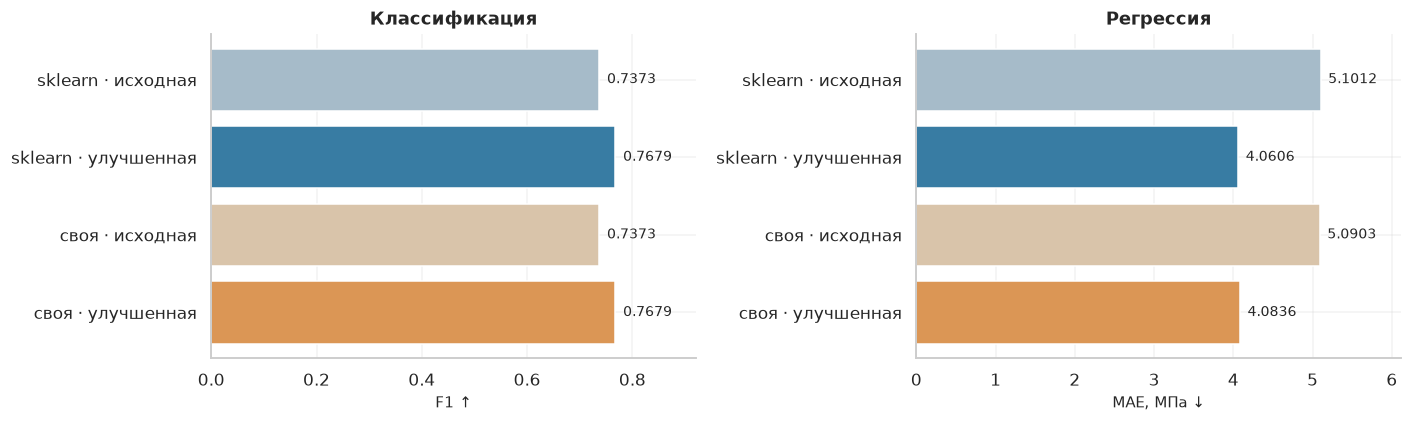

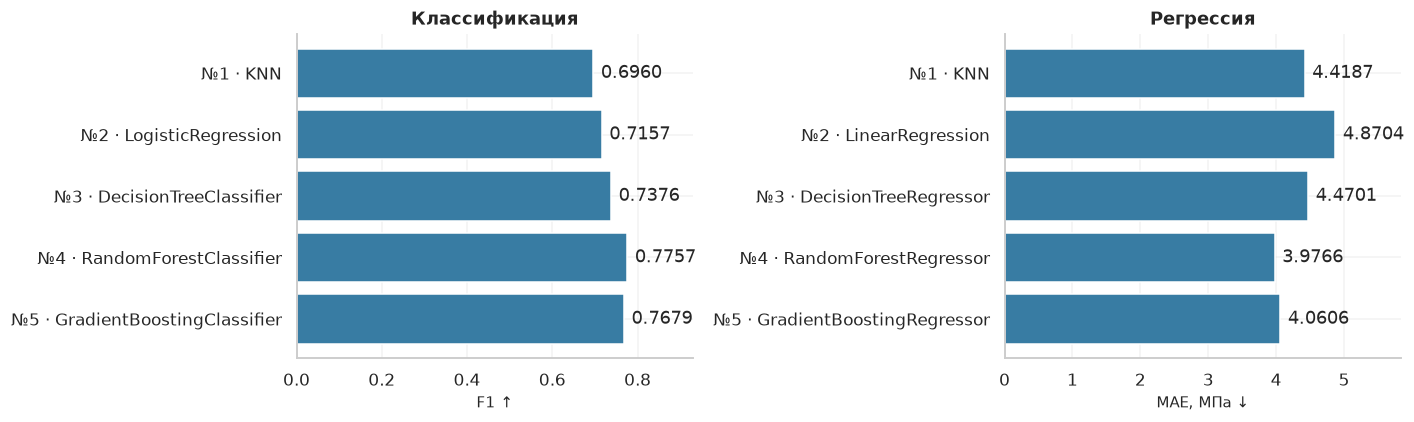

In [29]:
# Подписи значений позволяют увидеть небольшие разности без чтения шкалы.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task, metric in zip(axes, tasks, ["f1", "mae"]):
    group = metrics[(metrics.task==task)&(metrics.stage!="dummy")]
    bars = ax.barh([MODEL_NAMES[n] for n in group.model], group[metric],
                   color=["#a6bbc9","#387ca3","#d9c4aa","#db9655"])
    ax.bar_label(bars, fmt="%.4f", padding=5, fontsize=9)
    ax.set(title=TASK_NAMES[task], xlabel="F1 ↑" if metric=="f1" else "MAE, МПа ↓")
    ax.set_xlim(0,group[metric].max()*1.2)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1,2,figsize=(13,4))
previous = pd.DataFrame(previous_rows)
for ax,task in zip(axes,tasks):
    group=previous.query("task == @task")
    bars=ax.barh([f"№{row.lab} · {row.algorithm}" for row in group.itertuples()],group["Значение"])
    ax.bar_label(bars,fmt="%.4f",padding=5)
    ax.set(title=TASK_NAMES[task],xlabel="F1 ↑" if task=="classification" else "MAE, МПа ↓")
    ax.set_xlim(0,group["Значение"].max()*1.2)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Выводы и воспроизводимость

### Выводы по обязательным этапам

Сформирую численные выводы из текущих результатов. Они включают исходный бейзлайн,
эффект CV-подбора, отличие своей исходной модели, перенос техник и сравнение улучшенных
реализаций. Для F1 положительная разность полезна, для MAE — отрицательная.

In [30]:
# Все утверждения о качестве опираются на результаты этого запуска.
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    title = "F1" if task == "classification" else "MAE, МПа"
    m = metrics[metrics.task == task].set_index("model")
    config = selected[task]
    old, improved = m.loc["sklearn_baseline", metric], m.loc["sklearn_improved", metric]
    own_old, own_new = m.loc["custom_baseline", metric], m.loc["custom_improved", metric]
    better = improved > old if task == "classification" else improved < old
    own_better = own_new > own_old if task == "classification" else own_new < own_old
    base_cv = hypotheses[(hypotheses.task == task) & (hypotheses["mode"] == "raw")].iloc[0].cv_mean
    display(Markdown(
        f"**{TASK_NAMES[task]}.** Исходный sklearn: **{title} = {old:.5f}**, "
        f"улучшенный: **{improved:.5f}**; изменение **{improved-old:+.5f}**. "
        f"На данном test {'получено улучшение' if better else 'улучшения не получено'}. "
        f"CV-score изменился с **{base_cv:.5f}** до **{config['cv_score']:.5f}** "
        f"(для регрессии это отрицательная MAE). Выбраны признаки `{config['mode']}` "
        f"и параметры `{config['params']}`.\n\n"
        f"Своя исходная модель: **{own_old:.5f}**, разность со sklearn **{own_old-old:+.5f}**. "
        f"После переноса улучшений своя модель: **{own_new:.5f}**, "
        f"изменение **{own_new-own_old:+.5f}**; {'качество улучшилось' if own_better else 'выигрыша на test нет'}. "
        f"Разность с улучшенным sklearn: **{own_new-improved:+.5f}**. "
        "Различия связаны с составом подвыборок, равноценными порогами "
        "и численной арифметикой."))
    prior = pd.DataFrame(previous_rows).query("task == @task")
    best = prior.sort_values("Значение", ascending=task == "regression").iloc[0]
    display(Markdown(f"Среди улучшенных sklearn работ №1–5 на этом test лучший результат "
                     f"у **{best.algorithm} (№{int(best.lab)})**: **{best['Значение']:.5f}**. "
                     "Предобработка между алгоритмами различается, поэтому сравниваются полные решения."))

**Классификация.** Исходный sklearn: **F1 = 0.73733**, улучшенный: **0.76787**; изменение **+0.03054**. На данном test получено улучшение. CV-score изменился с **0.72872** до **0.76465** (для регрессии это отрицательная MAE). Выбраны признаки `engineered` и параметры `{'n_estimators': 200, 'learning_rate': 0.15, 'max_depth': 3, 'min_samples_leaf': 5, 'subsample': 1.0}`.

Своя исходная модель: **0.73733**, разность со sklearn **+0.00000**. После переноса улучшений своя модель: **0.76787**, изменение **+0.03054**; качество улучшилось. Разность с улучшенным sklearn: **+0.00000**. Различия связаны с составом подвыборок, равноценными порогами и численной арифметикой.

Среди улучшенных sklearn работ №1–5 на этом test лучший результат у **RandomForestClassifier (№4)**: **0.77569**. Предобработка между алгоритмами различается, поэтому сравниваются полные решения.

**Регрессия.** Исходный sklearn: **MAE, МПа = 5.10118**, улучшенный: **4.06058**; изменение **-1.04060**. На данном test получено улучшение. CV-score изменился с **-4.66824** до **-3.86711** (для регрессии это отрицательная MAE). Выбраны признаки `engineered` и параметры `{'n_estimators': 200, 'learning_rate': 0.15, 'max_depth': 3, 'min_samples_leaf': 3, 'subsample': 1.0}`.

Своя исходная модель: **5.09030**, разность со sklearn **-0.01088**. После переноса улучшений своя модель: **4.08358**, изменение **-1.00672**; качество улучшилось. Разность с улучшенным sklearn: **+0.02300**. Различия связаны с составом подвыборок, равноценными порогами и численной арифметикой.

Среди улучшенных sklearn работ №1–5 на этом test лучший результат у **RandomForestRegressor (№4)**: **3.97659**. Предобработка между алгоритмами различается, поэтому сравниваются полные решения.

### Содержательные итоги гипотез и дополнительных проверок

Соотнесу изменение precision/recall с F1, посмотрю изменение RMSE и R²,
условные bootstrap-интервалы, разброс seed и важные признаки.
Победителей по двум задачам определяю отдельно по улучшенным sklearn всех пяти работ.

In [31]:
# Выводы выводятся из фактических результатов, включая отсутствие выигрыша.
for task in tasks:
    m=metrics.query("task == @task").set_index("model"); s=selected[task]
    display(Markdown(f"**{TASK_NAMES[task]} — выбор по CV:** `{s['mode']}`, "
        f"M={s['params']['n_estimators']}, η={s['params']['learning_rate']}, "
        f"depth={s['params']['max_depth']}, leaf={s['params']['min_samples_leaf']}, "
        f"subsample={s['params']['subsample']}."))
    if task=="classification":
        display(Markdown(f"Precision sklearn: **{m.loc['sklearn_baseline','precision']:.3%} → {m.loc['sklearn_improved','precision']:.3%}**, "
            f"recall: **{m.loc['sklearn_baseline','recall']:.3%} → {m.loc['sklearn_improved','recall']:.3%}**. "
            "F1 нужно интерпретировать вместе с этими двумя составляющими."))
    else:
        display(Markdown(f"RMSE sklearn: **{m.loc['sklearn_baseline','rmse']:.5f} → {m.loc['sklearn_improved','rmse']:.5f} МПа**, "
            f"R²: **{m.loc['sklearn_baseline','r2']:.5f} → {m.loc['sklearn_improved','r2']:.5f}**. "
            "MAE оценивает обычный промах, RMSE сильнее реагирует на крупные ошибки."))
    for row in hypothesis_summary.query("task == @task").itertuples():
        display(Markdown(f"{row.experiment}: разность CV-score **{row.delta:+.5f}** "
            f"({'рост качества' if row.delta>0 else 'снижение качества' if row.delta<0 else 'качество совпало'} на исследованной сетке)."))
    seeds=pd.DataFrame(seed_records).query("task == @task")
    display(Markdown(f"Размах среднего CV-score по seed: **{seeds.cv_mean.max()-seeds.cv_mean.min():.5f}**; seed по этим результатам не меняю."))
    important=pd.DataFrame(importance_records).query("task == @task").nlargest(3,"importance")
    display(Markdown("Первые признаки по permutation importance: **"+", ".join(important.feature)+"**. Это зависимости модели, а не причинные эффекты."))
# Условные интервалы не учитывают переобучение моделей и поиск гиперпараметров.
for row in interval_rows:
    crosses=row["lower_95"] <= 0 <= row["upper_95"]
    display(Markdown(f"**{TASK_NAMES[row['task']]} · {row['comparison']}:** изменение **{row['delta']:+.5f}**, "
        f"условный 95% интервал **[{row['lower_95']:+.5f}; {row['upper_95']:+.5f}]**. "
        +( "Интервал включает ноль: знак эффекта неустойчив в этой проверке." if crosses else "Интервал не включает ноль в этой условной проверке.")))
for task in tasks:
    metric="f1" if task=="classification" else "mae"
    ranked=all_results[(all_results.task==task)&(all_results.model=="sklearn_improved")].sort_values(metric,ascending=task=="regression")
    winner=ranked.iloc[0]
    display(Markdown(f"**Итог №1–5, {TASK_NAMES[task]}:** лучший улучшенный sklearn на общем test — "
        f"**{winner.algorithm}, №{int(winner.lab)}**, {metric.upper()} = **{winner[metric]:.5f}**. "
        "Это рейтинг на одном исследовательском holdout."))

**Классификация — выбор по CV:** `engineered`, M=200, η=0.15, depth=3, leaf=5, subsample=1.0.

Precision sklearn: **86.957% → 85.705%**, recall: **64.000% → 69.550%**. F1 нужно интерпретировать вместе с этими двумя составляющими.

H1 · scaled − raw: разность CV-score **+0.00000** (качество совпало на исследованной сетке).

H2 · log − raw: разность CV-score **+0.00000** (качество совпало на исследованной сетке).

H3 · engineered − log: разность CV-score **+0.00038** (рост качества на исследованной сетке).

H4 · η=0.15 − 0.05: разность CV-score **+0.06594** (рост качества на исследованной сетке).

... (22 outputs left out)

**Регрессия · Улучшение sklearn:** изменение **-1.04060**, условный 95% интервал **[-1.64322; -0.48414]**. Интервал не включает ноль в этой условной проверке.

**Регрессия · Своя минус sklearn после улучшений:** изменение **+0.02300**, условный 95% интервал **[+0.00306; +0.05263]**. Интервал не включает ноль в этой условной проверке.

**Итог №1–5, Классификация:** лучший улучшенный sklearn на общем test — **RandomForestClassifier, №4**, F1 = **0.77569**. Это рейтинг на одном исследовательском holdout.

**Итог №1–5, Регрессия:** лучший улучшенный sklearn на общем test — **RandomForestRegressor, №4**, MAE = **3.97659**. Это рейтинг на одном исследовательском holdout.

### Сохранение протокола и проверяемые артефакты

Сохраню seed, версии, параметры baseline и победителей, пространство поиска, правила
отбора, источники и контрольные суммы данных/разбиений. `metrics.csv` совместим
с общей сводкой; индивидуальные прогнозы позволяют независимо пересчитать метрики.

In [32]:
# Полный протокол фиксирует последовательность отбора и особенности реализации.
reference=json.loads((ROOT/"lab_1/results/protocol.json").read_text())
protocol=dict(lab=5,seed=SEED,cv_folds=3,baseline={task:baseline_params(task) for task in tasks},
    selected=selected,classification_threshold=.5,classification_tie="class 0",
    losses={"classification":"binary log-loss with Newton leaf update","regression":"half squared error; report MSE"},
    search=dict(modes=["raw","engineered"],learning_rate=[.05,.15],max_depth=[2,3],subsample=[.7,1.],
        stages=STAGES,trajectories_per_task=17,additional="baseline representations and isolated leaf sizes",
        selection="max mean train-CV score; ties: fewer trees, smaller depth, candidate order",
        internal_early_stopping=False,all_training_rows=True),
    custom="own NumPy CART from lab_3; deterministic feature ties; NumPy default_rng; sampling without replacement",
    seed_robustness=[7,21,42],paired_bootstrap_repeats=500,
    datasets=reference["datasets"],
    versions=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,sklearn=sklearn.__version__))
(RESULTS/"protocol.json").write_text(json.dumps(protocol,ensure_ascii=False,indent=2))
# Проверки общей схемы и наличия всех обязательных вариантов.
assert len(metrics)==10 and not metrics.duplicated(["task","model"]).any()
for task in tasks:
    assert set(metrics.loc[metrics.task==task,"model"])==set(MODEL_NAMES)
    assert selected[task]["cv_score"] >= next(h["cv_mean"] for h in hypothesis_records if h["task"]==task and h["mode"]=="raw") - 1e-12
print("Сохранены метрики, прогнозы, CV, разбиения, диагностика и протокол.")
print("Артефактов:",len(list(RESULTS.iterdir())))

Сохранены метрики, прогнозы, CV, разбиения, диагностика и протокол.
Артефактов: 31


### Интерпретация сохранённого запуска

**Предобработка и параметры.** В кредитной задаче scaling и log не изменили CV F1;
новые отношения дали небольшой прирост **+0,00038**. Для бетона основной содержательный
эффект новых признаков заметнее: относительно log CV MAE снизилась на **0,534 МПа**.
Увеличение листа с 1 до 5/15 при исходных настройках немного ухудшило CV F1, но лист
от 5 вошёл в лучшую совместную конфигурацию. Эффект параметра зависит от остальных
настроек: отдельный неудачный опыт не исключает его полезность в другом сочетании.
Подвыборка 0,7 в среднем помогала на исследованной сетке, однако победители используют
все строки. Средний парный эффект по сетке и свойства конкретного победителя различаются.

Для обеих задач выбраны **engineered, 200 деревьев, η=0,15, depth=3, subsample=1**;
минимум в листе — **5** для заявок и **3** для бетона. Число деревьев и скорость оказались
на верхних границах поиска. Поэтому результат не доказывает оптимальность этих границ:
отдельное расширение сетки могло бы изменить выбор. Кривые train/CV показывают,
достаточно ли итераций в исследованном диапазоне, но не гарантируют дальнейшего улучшения.

**Классификация.** F1 sklearn вырос с **0,73733 до 0,76787**. Precision изменилась
с **86,96% до 85,71%**, recall — с **64,00% до 69,55%**. Прирост F1 сопровождается
большей полнотой при небольшом снижении точности. Парный условный интервал прироста
F1 **[+0,01974; +0,03988]** не включает ноль. Свои исходный и улучшенный классификаторы
совпали со sklearn по всем test-меткам; средняя абсолютная разность вероятностей после
улучшения — около **1,7·10⁻¹⁷**. Нулевой интервал разности F1 отражает совпадение этих
фиксированных предсказаний; это не утверждение о совпадении на любых данных.

**Регрессия.** MAE sklearn снизилась с **5,10118 до 4,06058 МПа**, RMSE —
с **7,01292 до 5,67134 МПа**, R² вырос с **0,84758 до 0,90032**.
Перенос улучшений в свою модель снизил MAE с **5,09030 до 4,08358 МПа**.
Средняя абсолютная разность прогнозов улучшенных реализаций — **0,04389 МПа**,
максимальная — **1,07333 МПа**. Своя MAE выше sklearn на **0,02300 МПа**;
условный парный интервал **[+0,00306; +0,05263] МПа** не включает ноль.
В этом сравнении знак небольшого разрыва устойчив к ресэмплингу test-рецептур,
но интервал не учитывает новое обучение и поиск настроек.

**Стабильность и затраты.** При subsample=1 исходные и улучшенные собственные модели
используют все train-строки без повторов. Потери train уменьшались на каждой итерации
этого запуска; в общем случае при стохастическом обучении это не гарантируется.
Средний CV F1 sklearn совпал для трёх seed, размах CV MAE бетона составил около
**0,019 МПа** из-за равноценных разбиений. Улучшенный собственный классификатор обучался
примерно **23,04 с** против **8,35 с** sklearn: проверка математики и близость качества
не означают одинаковую вычислительную эффективность.

**Итог №1–5.** На общем test улучшенный Random Forest сохранил лучший F1
(**0,77569**) и минимальную MAE (**3,97659 МПа**); бустинг получил **0,76787**
и **4,06058 МПа**. При этом бустинг имеет несколько меньшую RMSE бетона:
**5,67134 против 5,71237 МПа**. По основной средней абсолютной ошибке выигрывает лес,
а по сильнее штрафующей большие промахи RMSE — бустинг. Единственного лидера по всем
показателям нет. В [отдельной сводке](../comparison.ipynb) показаны все пять семейств,
четыре варианта каждой работы, время и прямое парное сравнение двух ансамблей.
Все оценки относятся к одному исследовательскому holdout.

### Общий вывод и ограничения

Я выполнил этапы лабораторной №5: построил классификатор и регрессор sklearn,
оценил исходные модели, проверил гипотезы на train-CV, выбрал улучшенные конфигурации,
реализовал бустинг и его базовые деревья без готовых ансамблей, обучил собственные
модели до и после переноса улучшений и сравнил четыре обязательные пары.
Общая таблица и графики включают **результаты всех лабораторных №1–5**.

Бустинг обучает последовательность поправок к текущему прогнозу. Для регрессии это
деревья остатков, для классификации — деревья отрицательного градиента с Newton-листьями.
Совместная настройка скорости и числа деревьев позволяет управлять силой поправок;
глубина, размер листа и подвыборка дополняют регуляризацию. Изменение масштабов само
по себе не создаёт новых направлений разбиений, а отношения компонентов могут это делать.
Полезность каждого приёма определяется результатами CV, приведёнными выше.

**Границы исследования.** Сетка ограничена: максимум 200 деревьев, глубина 2/3,
два шага и две доли строк; глобальный оптимум не гарантирован. Победитель найден по
тем же трём фолдам, на которых сравниваются кандидаты: лучший CV-score оптимистичен.
Проверки гипотез описательные, без поправки на множественные сравнения.
В собственной модели нет multiclass, sample weights, warm_start и автоматической
остановки; плотный числовой вход и пропуски подготавливает Pipeline.
При подвыборке собственный генератор не воспроизводит выборки sklearn побитово.

Общий test уже использовался для сравнения пяти семейств, поэтому он служит
исследовательским ориентиром. Для окончательного выбора модели требуется новый
holdout или вложенная CV. Bootstrap-интервалы условны относительно обученных моделей,
три seed не учитывают неопределённость нового разбиения, время измерено одним запуском.
Кредитные данные синтетические; историческое одобрение не равно будущему дефолту.
Групповое разбиение бетона исключает точные рецептуры, но не все близкие смеси.
Permutation importance не доказывает причинность. Численные итоги каждого этапа
и практический компромисс качества/времени приведены в таблицах и выводах выше.

### Повторный запуск

Из корня репозитория в общем окружении Python 3.12:

```bash
python run_notebooks.py --labs 5
python -m pytest -q
```

Первая команда выполнит №5 и обновит [отдельный итоговый notebook](../comparison.ipynb).
`python run_notebooks.py` выполняет все пять работ. Можно также открыть этот notebook
из корня или `lab_5` и выполнить **Run All**. Нужны данные и протокол №1;
сохранённые результаты №1–4 нужны для сравнения. Полный CV-поиск может занимать несколько минут.

### Источники

- [Описание данных, единицы и лицензии](../lab_1/data/README.md).
- [Friedman (2001), Greedy Function Approximation](https://doi.org/10.1214/aos/1013203451) — математическая постановка.
- [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) — параметры библиотечной классификации.
- [GradientBoostingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html) — параметры регрессии.
- [Руководство sklearn по ансамблям](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting) — описание бустинга.